## **Optimasi Rute Penjemputan Bahan dari Supplier**

Sebuah depot di Bunder, Cikupa, Kabupaten Tangerang, harus mengambil bahan dari 20 supplier di wilayah Tangerang. Armada yang tersedia adalah CDE Box dengan kapasitas 850 kg per kendaraan. Setiap kendaraan berangkat dari depot, mengunjungi satu atau lebih supplier, lalu kembali ke depot dalam satu rute. Seluruh bahan di setiap supplier harus terambil. Supplier dengan bahan di atas 850 kg boleh dilayani oleh beberapa kendaraan (*split pickup*). Setiap kunjungan harus berada dalam jam operasional supplier, dan kendaraan harus berangkat serta kembali dalam jam operasional depot. Perusahaan ingin meminimalkan jumlah kendaraan terlebih dahulu, lalu meminimalkan total jarak seluruh rute pada jumlah kendaraan tersebut.

Dataset tidak menyediakan waktu tempuh dan waktu bongkar-muat, sehingga dipakai asumsi kecepatan rata-rata 30 km/jam dan waktu pelayanan 1 jam per kunjungan.

**Node Locations:**

| Node | Lokasi | Kecamatan | Latitude | Longitude | Jam operasional | Bahan (kg) |
| :--- | :----- | :-------- | :------- | :-------- | :-------------- | :--------- |
| 0 | Depot | Cikupa | -6.188692 | 106.537143 | 07:00–17:00 | – |
| 1 | Supplier A | Serpong | -6.235232 | 106.644512 | 08:00–17:00 | 478 |
| 2 | Supplier B | Cisauk | -6.247438 | 106.565049 | 08:00–17:00 | 3.293 |
| 3 | Supplier C | Batu Ceper | -6.156817 | 106.664965 | 08:30–17:00 | 75 |
| 4 | Supplier D | Cibodas | -6.204664 | 106.596086 | 08:00–16:30 | 6.923 |
| 5 | Supplier E | Kosambi | -6.082341 | 106.707870 | 08:00–16:00 | 628 |
| 6 | Supplier F | Jatiuwung | -6.188051 | 106.535928 | 08:00–17:00 | 431 |
| 7 | Supplier G | Kec. Kosambi | -6.097955 | 106.644930 | 07:00–16:00 | 318 |
| 8 | Supplier H | Kec. Benda | -6.116258 | 106.682931 | 08:00–17:00 | 185 |
| 9 | Supplier I | Setu | -6.330117 | 106.675790 | 08:00–17:00 | 600 |
| 10 | Supplier J | Batu Ceper | -6.159178 | 106.663208 | 08:30–17:30 | 1.430 |
| 11 | Supplier K | Setu | -6.338169 | 106.680919 | 09:00–16:00 | 168 |
| 12 | Supplier L | Kelapa Dua | -6.267520 | 106.594269 | 08:00–16:00 | 5 |
| 13 | Supplier M | Jatiuwung | -6.210653 | 106.588759 | 09:00–17:00 | 1.265 |
| 14 | Supplier N | Batu Ceper | -6.164062 | 106.666582 | 08:00–17:00 | 1.945 |
| 15 | Supplier O | Karawaci | -6.164890 | 106.612213 | 07:30–16:30 | 3.298 |
| 16 | Supplier P | CIKUPA | -6.256287 | 106.486590 | 08:00–17:00 | 935 |
| 17 | Supplier Q | Setu | -6.335008 | 106.671623 | 08:00–17:00 | 345 |
| 18 | Supplier R | BSD | -6.333079 | 106.675601 | 08:30–16:00 | 370 |
| 19 | Supplier S | Pondok Aren | -6.266305 | 106.718389 | 08:00–17:00 | 480 |
| 20 | Supplier T | Kec. Jatiuwung | -6.195817 | 106.553965 | 08:00–17:00 | 460 |

## **A. Model Matematis**

Berikut formulasi *split-delivery* CVRP dengan *time windows* Formulasi ini mendefinisikan masalah beserta seluruh batasannya. Notebook ini menyelesaikannya dengan heuristik *greedy nearest neighbour* (Bagian 2) dan *genetic algorithm* (Bagian 4), sehingga solusi yang dihasilkan memenuhi constraint (diperiksa pada bagian audit) tetapi tidak dijamin meminimalkan fungsi tujuan. Setiap kendaraan mempunyai satu lingkaran (*circuit*) sendiri atas lokasi yang ia kunjungi.

### **Himpunan:**
*   $N = \{0, 1, \dots, 20\}$: himpunan seluruh lokasi, dengan $0$ sebagai depot, diindeks oleh $i, j$.
*   $S = N \setminus \{0\}$: himpunan 20 supplier.
*   $V = \{1, \dots, K\}$: himpunan kendaraan CDE Box, diindeks oleh $v$.

### **Parameter:**
*   $d_{ij}$: Jarak dari lokasi $i$ ke lokasi $j$ (meter). Berasal dari matriks jarak jalan OSRM, atau Haversine jika matriks jalan tidak tersedia.
*   $t_{ij} = \left\lceil \dfrac{d_{ij}/1000}{\bar{v}} \times 60 \right\rceil$: Waktu tempuh dari $i$ ke $j$ (menit), dengan $\bar{v} = 30$ km/jam.
*   $q_i$: Jumlah bahan yang harus diambil di supplier $i$ (kg), yaitu kolom `CAPACITY`.
*   $Q = 850$: Kapasitas satu kendaraan CDE Box (kg).
*   $s = 60$: Waktu pelayanan per kunjungan (menit), yaitu 1 jam. Ini adalah asumsi karena dataset tidak menyediakan waktu bongkar-muat.
*   $[a_i, b_i]$: Jam operasional lokasi $i$ (menit sejak 00:00). Untuk depot, $[a_0, b_0] = [07{:}00, 17{:}00]$.
*   $K = \sum_{i \in S} \lceil q_i / Q \rceil$: Jumlah kendaraan maksimum yang disediakan model.
*   $L = \left\lceil \sum_{i \in S} q_i / Q \right\rceil$: Batas bawah jumlah kendaraan.

### **Decision Variables:**
*   $x_{vij}$: Variabel biner, $x_{vij} = 1$ jika kendaraan $v$ bergerak langsung dari lokasi $i$ ke lokasi $j$ ($i \neq j$), dan $0$ jika tidak.
*   $x_{vii}$: Variabel biner *self-loop*, $x_{vii} = 1$ jika kendaraan $v$ **tidak** mengunjungi lokasi $i$. Untuk depot, $x_{v00} = 1$ berarti kendaraan $v$ tidak dipakai.
*   $z_{vi} = 1 - x_{vii}$: Indikator bahwa kendaraan $v$ mengunjungi supplier $i$.
*   $u_v$: Variabel biner, $u_v = 1$ jika kendaraan $v$ dipakai.
*   $p_{vi}$: Variabel integer, jumlah bahan (kg) yang diambil kendaraan $v$ di supplier $i$.
*   $\ell_v$: Variabel integer, total muatan kendaraan $v$ (kg).
*   $\tau_{vi}$: Variabel integer, waktu kendaraan $v$ tiba dan mulai melayani supplier $i$ (menit). Kendaraan boleh menunggu hingga jam buka.
*   $\delta_v$: Variabel integer, waktu kendaraan $v$ berangkat dari depot (menit).

### **Objective Function:**
Optimasi dilakukan berurutan (*lexicographic*).

Tahap 1, minimalkan jumlah kendaraan:
$$\text{Minimize } \sum_{v \in V} u_v$$

Tahap 2, kunci jumlah kendaraan terbaik $K^*$ dari tahap 1, lalu minimalkan total jarak:
$$\text{Minimize } \sum_{v \in V} \sum_{i \in N} \sum_{j \in N, i \neq j} d_{ij} \, x_{vij} \quad \text{s.t.} \quad \sum_{v \in V} u_v = K^*$$

### **Constraints:**
1.  Setiap kendaraan membentuk satu lingkaran tunggal yang terhubung melalui depot, dan lokasi yang tidak dikunjungi memakai *self-loop* (*circuit constraint*, pengganti MTZ):
    $$\{x_{vij}\}_{i,j \in N} \text{ membentuk satu circuit} \quad \forall v \in V$$
    Setiap lokasi yang dikunjungi memiliki tepat satu busur masuk dan satu busur keluar:
    $$\sum_{j \in N, j \neq i} x_{vij} = 1 - x_{vii} \quad \text{dan} \quad \sum_{j \in N, j \neq i} x_{vji} = 1 - x_{vii} \quad \forall v \in V, \forall i \in N$$

2.  Kendaraan dipakai jika dan hanya jika meninggalkan depot:
    $$x_{v00} + u_v = 1 \quad \forall v \in V$$

3.  Pengambilan bahan hanya terjadi pada supplier yang dikunjungi, dan jika dikunjungi, minimal 1 kg diambil:
    $$z_{vi} \le p_{vi} \le \min(q_i, Q) \, z_{vi} \quad \forall v \in V, \forall i \in S$$

4.  Seluruh bahan setiap supplier harus terambil (*split pickup* diperbolehkan):
    $$\sum_{v \in V} p_{vi} = q_i \quad \forall i \in S$$

5.  Muatan kendaraan tidak boleh melebihi kapasitas, dan kendaraan yang dipakai membawa muatan:
    $$\ell_v = \sum_{i \in S} p_{vi}, \qquad u_v \le \ell_v \le Q \, u_v \quad \forall v \in V$$

6.  Kunjungan berada dalam jam operasional supplier (termasuk waktu pelayanan):
    $$z_{vi} = 1 \;\Rightarrow\; a_i \le \tau_{vi} \quad \text{dan} \quad \tau_{vi} + s \le b_i \quad \forall v \in V, \forall i \in S$$

7.  Kesinambungan waktu sepanjang rute:
    $$x_{v0j} = 1 \;\Rightarrow\; \tau_{vj} \ge \delta_v + t_{0j} \quad \forall v \in V, \forall j \in S$$
    $$x_{vij} = 1 \;\Rightarrow\; \tau_{vj} \ge \tau_{vi} + s + t_{ij} \quad \forall v \in V, \forall i, j \in S, i \neq j$$
    $$x_{vi0} = 1 \;\Rightarrow\; \tau_{vi} + s + t_{i0} \le b_0 \quad \forall v \in V, \forall i \in S$$

8.  Jam keberangkatan dari depot berada dalam jam operasional depot:
    $$a_0 \le \delta_v \le b_0 \quad \forall v \in V$$

9.  Batas bawah jumlah kendaraan dan pemecah simetri antar kendaraan identik:
    $$\sum_{v \in V} u_v \ge L, \qquad u_v \ge u_{v+1}, \qquad \ell_v \ge \ell_{v+1} \quad \forall v \in \{1, \dots, K-1\}$$

10. Domain variabel:
    $$x_{vij}, u_v \in \{0, 1\}; \quad p_{vi}, \ell_v, \tau_{vi}, \delta_v \in \mathbb{Z}_{\ge 0}$$

### **Specific Values for this problem:**
*   **Jumlah lokasi ($|N|$):** 21 lokasi (node 0 sampai 20, termasuk depot), dengan 20 supplier.
*   **Total bahan ($\sum q_i$):** 23.632 kg.
*   **Batas bawah kendaraan ($L$):** $\lceil 23.632 / 850 \rceil = 28$ kendaraan.
*   **Kendaraan maksimum ($K$):** 39 kendaraan, karena tujuh supplier (B, D, J, M, N, O, P) memerlukan lebih dari satu kendaraan dan 13 supplier lainnya masing-masing satu.
*   **Matriks jarak ($d_{ij}$):** jarak jalan OSRM (tidak harus simetris), dibulatkan ke meter.
*   **Depot:** Node 0 (Bunder, Cikupa), dengan jam operasional 07:00–17:00.

# 1. Membaca Dataset SC di Google Colab

Bagian ini menggunakan `Dataset SC.xlsx` secara langsung:

- sheet `ETS` berisi depot, 20 supplier, koordinat, jam operasional, dan kapasitas bahan;
- sheet `Sheet2` berisi komponen tarif armada;
- baris `CDE Box` dipilih sebagai armada dengan kapasitas 850 kg.

## Instalasi dan konfigurasi


In [57]:

%pip -q install pandas openpyxl folium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
from datetime import time
from pathlib import Path
import math
import re

import folium
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

WORK_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_FILE = str(WORK_DIR / "Dataset SC.xlsx")
LOCATION_SHEET = "ETS"
COST_SHEET = "Sheet2"
VEHICLE_TYPE = "CDE Box"
VEHICLE_CAPACITY_KG = 850

ROAD_DISTANCE_MATRIX_FILE = None
ROAD_DISTANCE_MATRIX_SHEET = 0
ROAD_DISTANCE_MATRIX_UNIT = "km"

#Asumsi waktu rata-rata perjalanan 30 km/jam dan waktu pelayanan 60 menit per kunjungan
AVERAGE_SPEED_KMPH = 30
SERVICE_MINUTES_PER_VISIT = 60
USE_TIME_WINDOWS = True

## Unggah workbook


In [60]:
if not Path(DATA_FILE).exists():
    if not IN_COLAB:
        raise FileNotFoundError(f"Letakkan Dataset SC.xlsx di folder kerja: {WORK_DIR}")
    print("Unggah file Dataset SC.xlsx")
    uploaded = files.upload()
    xlsx_files = [name for name in uploaded if Path(name).suffix.lower() == ".xlsx"]
    if len(xlsx_files) != 1:
        raise ValueError("Unggah tepat satu workbook XLSX.")
    DATA_FILE = xlsx_files[0]

workbook = pd.ExcelFile(DATA_FILE)
required_sheets = {LOCATION_SHEET, COST_SHEET}
missing_sheets = required_sheets - set(workbook.sheet_names)
if missing_sheets:
    raise ValueError(f"Sheet tidak ditemukan: {sorted(missing_sheets)}")

raw_locations = pd.read_excel(DATA_FILE, sheet_name=LOCATION_SHEET)
raw_costs = pd.read_excel(DATA_FILE, sheet_name=COST_SHEET)

print(f"Workbook: {DATA_FILE}")
display(raw_locations.head())
display(raw_costs)


Workbook: c:\SC\Dataset SC.xlsx


,NAMA SUPPLIER,ALAMAT GUDANG SUPPLIER,LAT,LONG,START JAM OPERASIONAL,END JAM OPERASIONAL,KECAMATAN,KABUPATEN/KOTA,PROVINSI,CAPACITY
0,Depot,"Bunder, Kec. Cikupa, Kabupaten Tangerang, Bant...",-6.188692,106.537143,07:00:00,17:00:00,Cikupa,Kabupaten Tangerang,Banten,NaN
1,Supplier A,Jl. MH. Thamrin Km. 7. Komp. Multiguna Blok D ...,-6.235232,106.644512,08:00:00,17:00:00,Serpong,Tangerang,Banten,478.0
2,Supplier B,"JL RAYA CURUG RAYA KM 3 NO 110, SUKABAKTI, CUR...",-6.247438,106.565049,08:00:00,17:00:00,Cisauk,Kabupaten Tangerang,Banten,3293.0
3,Supplier C,"DAAN MOGOT ARCADIA, BLOK G18 no 5, Jln Daan Mo...",-6.156817,106.664965,08:30:00,17:00:00,Batu Ceper,Kota Tangerang,Banten,75.0
4,Supplier D,"Gatot Subroto KM.4 Jl. Kalisabi No 1, Jati Uwu...",-6.204664,106.596086,08:00:00,16:30:00,Cibodas,Kota Tangerang,Banten,6923.0


,JENIS TRUK,DELIVERY FEE,EXTRA HELPER,TOL,PAJAK
0,CDE Box,753300,95.0,150000,21.963


## Menyiapkan lokasi, kapasitas, dan jam operasional


In [61]:
LOCATION_COLUMNS = {
    "NAMA SUPPLIER 1": "supplier_name",
    "ALAMAT GUDANG SUPPLIER": "address",
    "LAT": "latitude",
    "LONG": "longitude",
    "START JAM OPERASIONAL": "window_start_raw",
    "END JAM OPERASIONAL": "window_end_raw",
    "KECAMATAN": "district",
    "KABUPATEN/KOTA": "city",
    "PROVINSI": "province",
    "CAPACITY": "demand_kg",
}


def to_minute_of_day(value):
    if pd.isna(value):
        raise ValueError("Jam operasional tidak boleh kosong.")
    if isinstance(value, time):
        return value.hour * 60 + value.minute
    parsed = pd.to_datetime(str(value), errors="raise")
    return parsed.hour * 60 + parsed.minute


def make_location_id(name):
    normalized = re.sub(r"[^A-Z0-9]+", "_", str(name).upper()).strip("_")
    return "DEPOT" if normalized == "DEPOT" else normalized


def prepare_locations(raw_frame):
    raw_frame = raw_frame.rename(columns={"NAMA SUPPLIER": "NAMA SUPPLIER 1"})
    missing = [column for column in LOCATION_COLUMNS if column not in raw_frame.columns]
    if missing:
        raise ValueError(f"Kolom sheet ETS tidak lengkap: {missing}")

    frame = raw_frame[list(LOCATION_COLUMNS)].rename(columns=LOCATION_COLUMNS).copy()
    frame["supplier_name"] = frame["supplier_name"].astype(str).str.strip()
    frame["location_id"] = frame["supplier_name"].map(make_location_id)
    frame["is_depot"] = frame["supplier_name"].str.casefold().eq("depot")
    frame["demand_kg"] = pd.to_numeric(frame["demand_kg"], errors="coerce")
    frame.loc[frame["is_depot"], "demand_kg"] = 0

    for column in ["latitude", "longitude"]:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    frame["window_start"] = frame["window_start_raw"].map(to_minute_of_day)
    frame["window_end"] = frame["window_end_raw"].map(to_minute_of_day)

    errors = []
    if frame["is_depot"].sum() != 1:
        errors.append("Harus ada tepat satu baris Depot.")
    if frame["location_id"].duplicated().any():
        errors.append("Nama lokasi menghasilkan location_id yang duplikat.")
    if frame[["latitude", "longitude", "demand_kg"]].isna().any().any():
        errors.append("Koordinat atau CAPACITY mengandung nilai kosong/bukan angka.")
    if not frame["latitude"].between(-90, 90).all():
        errors.append("LAT harus berada pada rentang -90 sampai 90.")
    if not frame["longitude"].between(-180, 180).all():
        errors.append("LONG harus berada pada rentang -180 sampai 180.")
    if not frame.loc[~frame["is_depot"], "demand_kg"].gt(0).all():
        errors.append("CAPACITY setiap supplier harus lebih besar dari 0.")
    if not frame["window_start"].lt(frame["window_end"]).all():
        errors.append("START JAM OPERASIONAL harus lebih awal dari END JAM OPERASIONAL.")
    if errors:
        raise ValueError("\n- " + "\n- ".join(errors))

    frame["demand_kg"] = frame["demand_kg"].round().astype(int)
    depot = frame.loc[frame["is_depot"]]
    suppliers = frame.loc[~frame["is_depot"]]
    ordered = pd.concat([depot, suppliers], ignore_index=True)
    return ordered.drop(columns=["window_start_raw", "window_end_raw"])


locations = prepare_locations(raw_locations)
supplier_count = len(locations) - 1
total_demand_kg = int(locations["demand_kg"].sum())
vehicle_lower_bound = math.ceil(total_demand_kg / VEHICLE_CAPACITY_KG)
direct_trip_upper_bound = int(
    sum(math.ceil(value / VEHICLE_CAPACITY_KG) for value in locations.loc[1:, "demand_kg"])
)

print(f"Jumlah supplier               : {supplier_count}")
print(f"Total bahan                   : {total_demand_kg:,} kg")
print(f"Kapasitas CDE box             : {VEHICLE_CAPACITY_KG:,} kg")
print(f"Batas bawah jumlah kendaraan  : {vehicle_lower_bound}")
print(f"Batas atas perjalanan langsung: {direct_trip_upper_bound}")
display(locations)


Jumlah supplier               : 20
Total bahan                   : 23,632 kg
Kapasitas CDE box             : 850 kg
Batas bawah jumlah kendaraan  : 28
Batas atas perjalanan langsung: 39


,supplier_name,address,latitude,longitude,district,city,province,demand_kg,location_id,is_depot,window_start,window_end
0,Depot,"Bunder, Kec. Cikupa, Kabupaten Tangerang, Bant...",-6.188692,106.537143,Cikupa,Kabupaten Tangerang,Banten,0,DEPOT,True,420,1020
1,Supplier A,Jl. MH. Thamrin Km. 7. Komp. Multiguna Blok D ...,-6.235232,106.644512,Serpong,Tangerang,Banten,478,SUPPLIER_A,False,480,1020
2,Supplier B,"JL RAYA CURUG RAYA KM 3 NO 110, SUKABAKTI, CUR...",-6.247438,106.565049,Cisauk,Kabupaten Tangerang,Banten,3293,SUPPLIER_B,False,480,1020
3,Supplier C,"DAAN MOGOT ARCADIA, BLOK G18 no 5, Jln Daan Mo...",-6.156817,106.664965,Batu Ceper,Kota Tangerang,Banten,75,SUPPLIER_C,False,510,1020
4,Supplier D,"Gatot Subroto KM.4 Jl. Kalisabi No 1, Jati Uwu...",-6.204664,106.596086,Cibodas,Kota Tangerang,Banten,6923,SUPPLIER_D,False,480,990
5,Supplier E,"PERGUDANGAN PANTAI INDAH DADAP BLOK BH 36-37, ...",-6.082341,106.707870,Kosambi,Kabupaten Tangerang,Banten,628,SUPPLIER_E,False,480,960
6,Supplier F,"Jl. Industri Raya IV Blok Ai No. 54, Kawasan I...",-6.188051,106.535928,Jatiuwung,Kota Tangerang,Banten,431,SUPPLIER_F,False,480,1020
7,Supplier G,Jl. Raya Prancis No. 2 Pergudangan Harapan Dad...,-6.097955,106.644930,Kec. Kosambi,Kab. Tangerang – Banten,Banten,318,SUPPLIER_G,False,420,960
8,Supplier H,Pergudangan Zoodia Business Park Unit No. 19 J...,-6.116258,106.682931,Kec. Benda,Kota Tangerang,Banten,185,SUPPLIER_H,False,480,1020
9,Supplier I,"Taman Tekno BSD Sektor XI, H-2, 30, Setu, Setu...",-6.330117,106.675790,Setu,Kota Tangerang Selatan,Banten,600,SUPPLIER_I,False,480,1020


## Membaca komponen biaya CDE Box


In [62]:
def prepare_vehicle_cost(raw_frame, vehicle_type):
    normalized = raw_frame.copy()
    normalized.columns = [str(column).strip().upper() for column in normalized.columns]
    required = ["JENIS TRUK", "DELIVERY FEE", "EXTRA HELPER", "TOL", "PAJAK"]
    missing = [column for column in required if column not in normalized.columns]
    if missing:
        raise ValueError(f"Kolom sheet biaya tidak lengkap: {missing}")
    match = normalized["JENIS TRUK"].astype(str).str.strip().str.casefold().eq(vehicle_type.casefold())
    if match.sum() != 1:
        raise ValueError(f"Baris biaya {vehicle_type!r} harus tepat satu.")
    return normalized.loc[match, required].iloc[0].to_dict()


vehicle_cost = prepare_vehicle_cost(raw_costs, VEHICLE_TYPE)
display(pd.DataFrame([vehicle_cost]))


,JENIS TRUK,DELIVERY FEE,EXTRA HELPER,TOL,PAJAK
0,CDE Box,753300,95.0,150000,21.963


## Matriks jarak jalan dari OSRM

Haversine hanya mengukur jarak garis lurus antarkoordinat, sehingga tidak mencerminkan rute yang benar-benar dilalui kendaraan. Bagian ini mengambil jarak jalan sebenarnya dari OSRM (*Open Source Routing Machine*), mesin rute berbasis data jalan OpenStreetMap.

Cara kerja cell berikut:

- seluruh 21 lokasi (depot dan 20 supplier) dikirim dalam satu permintaan ke layanan `table` OSRM untuk memperoleh matriks jarak jalan antarlokasi;
- matriks disimpan ke `/content/osrm_road_matrix_km.csv` dalam satuan km, sehingga saat cell dijalankan ulang file ini dipakai kembali tanpa memanggil server lagi;
- `ROAD_DISTANCE_MATRIX_FILE` diarahkan ke file tersebut, sehingga cell matriks jarak berikutnya otomatis memakai jarak jalan, bukan Haversine;
- jarak setiap titik ke jalan terdekat ditampilkan; titik yang berjarak lebih dari 300 m dari jalan ditandai agar koordinat `LAT`/`LONG`-nya diperiksa kembali.

Catatan:

- jarak jalan dapat berbeda menurut arah (A→B tidak selalu sama dengan B→A) karena adanya jalan satu arah;
- server OSRM yang dipakai adalah server publik gratis tanpa jaminan ketersediaan; jika server utama gagal, cell otomatis mencoba server cadangan;
- OSRM tidak memperhitungkan kondisi lalu lintas maupun pembatasan khusus kendaraan barang;
- waktu tempuh tetap dihitung dari asumsi `AVERAGE_SPEED_KMPH`, tetapi kini berdasarkan jarak jalan.

Jika file `osrm_road_matrix_km.csv` dihapus atau runtime Colab diganti, matriks akan diambil ulang dari server.

In [63]:
import time as _time
import requests

OSRM_SERVERS = [
    "https://routing.openstreetmap.de/routed-car",  # FOSSGIS public OSRM server (max 1 request/second)
    "https://router.project-osrm.org",              # OSRM demo server, dipakai kalo yg pertama fail
]
OSRM_HEADERS = {"User-Agent": "Optimasi-Rute-SC/1.0 (university course project, Google Colab)"}
ROAD_MATRIX_CSV = WORK_DIR / "osrm_road_matrix_km.csv"
_osrm_last_call = [0.0]


def osrm_request(service, coords_lonlat, params):
    """Call an OSRM service ('table' or 'route'), respecting 1 request/second, with server fallback."""
    coord_str = ";".join(f"{lon:.6f},{lat:.6f}" for lon, lat in coords_lonlat)
    errors = []
    for base in OSRM_SERVERS:
        url = f"{base}/{service}/v1/driving/{coord_str}"
        for attempt in range(3):
            wait = 1.1 - (_time.time() - _osrm_last_call[0])
            if wait > 0:
                _time.sleep(wait)
            _osrm_last_call[0] = _time.time()
            try:
                response = requests.get(url, params=params, headers=OSRM_HEADERS, timeout=60)
                payload = response.json() if response.headers.get("content-type", "").startswith("application/json") else {}
                if response.status_code == 200 and payload.get("code") == "Ok":
                    return payload
                errors.append(f"{base}: HTTP {response.status_code} {payload.get('message', response.text[:100])}")
                if response.status_code == 400:      # bad request: retrying will not help
                    break
            except requests.RequestException as error:
                errors.append(f"{base}: {error}")
            _time.sleep(2 * (attempt + 1))
    raise RuntimeError("Semua server OSRM gagal:\n- " + "\n- ".join(errors[-6:]))


osrm_coords = list(zip(locations["longitude"], locations["latitude"]))

if not ROAD_MATRIX_CSV.exists():
    table = osrm_request("table", osrm_coords, {"annotations": "distance,duration"})
    road_km = pd.DataFrame(table["distances"], dtype=float) / 1000
    if road_km.isna().any().any():
        raise ValueError("OSRM tidak menemukan rute jalan untuk sebagian pasangan lokasi.")
    road_km.index = road_km.columns = locations["location_id"].tolist()
    road_km.rename_axis("location_id").round(3).to_csv(ROAD_MATRIX_CSV)

    # How far OSRM had to move each point to reach the nearest road (large values = check coordinates)
    snap = pd.DataFrame({
        "location": locations["supplier_name"],
        "snap_to_road_m": [round(wp["distance"]) for wp in table["sources"]],
        "nearest_road": [wp.get("name") or "-" for wp in table["sources"]],
    })
    far = snap[snap["snap_to_road_m"] > 300]
    print("Jarak titik ke jalan terdekat (m):")
    display(snap)
    if len(far):
        print("PERHATIAN: koordinat berikut > 300 m dari jalan, periksa LAT/LONG-nya:", far["location"].tolist())
    print(f"Matriks jarak jalan disimpan: {ROAD_MATRIX_CSV}")
else:
    print(f"Memakai matriks jarak jalan yang sudah ada: {ROAD_MATRIX_CSV}")

# Hand the CSV to the notebook's existing, validated loader in the next cell
ROAD_DISTANCE_MATRIX_FILE = str(ROAD_MATRIX_CSV)
ROAD_DISTANCE_MATRIX_UNIT = "km"

Memakai matriks jarak jalan yang sudah ada: c:\SC\osrm_road_matrix_km.csv


# 2. Heuristik Greedy Nearest Neighbour untuk Split-Delivery CVRP

Bagian ini menyusun rute dengan algoritma *greedy nearest neighbour* (tetangga terdekat). Algoritma membangun rute satu kendaraan demi satu kendaraan dengan aturan berikut:

1. Kendaraan baru berangkat dari depot pada jam buka depot dengan sisa kapasitas 850 kg.
2. Dari lokasi saat ini, pilih supplier **terdekat** (menurut matriks jarak) yang masih memiliki sisa bahan dan masih layak dikunjungi, yaitu kendaraan sempat selesai melayani sebelum supplier tutup dan masih sempat kembali ke depot sebelum depot tutup. Kendaraan boleh menunggu jika tiba sebelum supplier buka.
3. Ambil bahan sebanyak yang lebih kecil antara sisa bahan supplier dan sisa kapasitas kendaraan. Jika bahan supplier belum habis, sisanya diambil kendaraan berikutnya (*split pickup*).
4. Ulangi langkah 2 dan 3 sampai kendaraan penuh atau tidak ada supplier yang layak, lalu kembali ke depot.
5. Mulai kendaraan baru dan ulangi sampai seluruh bahan terambil.

## Matriks jarak dan waktu tempuh

Jika tidak ada matriks jalan, notebook memakai Haversine. Haversine adalah jarak garis lurus; gunakan matriks jarak jalan bila hasil akan dipakai untuk keputusan operasional.


In [64]:
def haversine_distance_m(lat_1, lon_1, lat_2, lon_2):
    earth_radius_m = 6_371_008.8
    phi_1 = math.radians(lat_1)
    phi_2 = math.radians(lat_2)
    delta_phi = math.radians(lat_2 - lat_1)
    delta_lambda = math.radians(lon_2 - lon_1)
    value = (
        math.sin(delta_phi / 2) ** 2
        + math.cos(phi_1) * math.cos(phi_2) * math.sin(delta_lambda / 2) ** 2
    )
    return int(round(2 * earth_radius_m * math.asin(math.sqrt(value))))


def build_haversine_matrix(frame):
    size = len(frame)
    matrix = np.zeros((size, size), dtype=np.int64)
    for origin in range(size):
        for destination in range(size):
            if origin == destination:
                continue
            matrix[origin, destination] = haversine_distance_m(
                frame.at[origin, "latitude"],
                frame.at[origin, "longitude"],
                frame.at[destination, "latitude"],
                frame.at[destination, "longitude"],
            )
    return matrix


def load_road_distance_matrix(path, frame, sheet_name=0, unit="km"):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        raw_matrix = pd.read_csv(path)
    elif path.suffix.lower() == ".xlsx":
        raw_matrix = pd.read_excel(path, sheet_name=sheet_name)
    else:
        raise ValueError("Matriks jalan harus berformat CSV atau XLSX.")

    id_column = raw_matrix.columns[0]
    matrix_frame = raw_matrix.set_index(id_column)
    matrix_frame.index = matrix_frame.index.astype(str).str.strip()
    matrix_frame.columns = matrix_frame.columns.astype(str).str.strip()
    expected_ids = frame["location_id"].tolist()
    missing_rows = sorted(set(expected_ids) - set(matrix_frame.index))
    missing_columns = sorted(set(expected_ids) - set(matrix_frame.columns))
    if missing_rows or missing_columns:
        raise ValueError(
            f"ID matriks tidak lengkap. Baris hilang: {missing_rows}; "
            f"kolom hilang: {missing_columns}"
        )

    matrix_frame = matrix_frame.loc[expected_ids, expected_ids].apply(pd.to_numeric, errors="coerce")
    if matrix_frame.isna().any().any():
        raise ValueError("Matriks jalan mengandung nilai kosong atau bukan angka.")
    if (matrix_frame.to_numpy() < 0).any():
        raise ValueError("Matriks jalan tidak boleh bernilai negatif.")
    if not np.allclose(np.diag(matrix_frame.to_numpy()), 0):
        raise ValueError("Diagonal matriks jalan harus 0.")

    multipliers = {"m": 1, "meter": 1, "km": 1000, "kilometer": 1000}
    unit_key = unit.strip().lower()
    if unit_key not in multipliers:
        raise ValueError("ROAD_DISTANCE_MATRIX_UNIT harus 'meter' atau 'km'.")
    return np.rint(matrix_frame.to_numpy() * multipliers[unit_key]).astype(np.int64)


if ROAD_DISTANCE_MATRIX_FILE:
    distance_matrix_m = load_road_distance_matrix(
        ROAD_DISTANCE_MATRIX_FILE,
        locations,
        ROAD_DISTANCE_MATRIX_SHEET,
        ROAD_DISTANCE_MATRIX_UNIT,
    )
    distance_source = f"matriks jalan: {ROAD_DISTANCE_MATRIX_FILE}"
else:
    distance_matrix_m = build_haversine_matrix(locations)
    distance_source = "Haversine (garis lurus)"

travel_time_matrix_min = np.ceil(
    distance_matrix_m / 1000 / AVERAGE_SPEED_KMPH * 60
).astype(np.int64)

print(f"Sumber jarak: {distance_source}")
display(
    pd.DataFrame(
        distance_matrix_m / 1000,
        index=locations["location_id"],
        columns=locations["location_id"],
    ).round(3)
)


Sumber jarak: matriks jalan: c:\SC\osrm_road_matrix_km.csv


location_id,DEPOT,SUPPLIER_A,SUPPLIER_B,SUPPLIER_C,SUPPLIER_D,SUPPLIER_E,SUPPLIER_F,SUPPLIER_G,SUPPLIER_H,SUPPLIER_I,...,SUPPLIER_K,SUPPLIER_L,SUPPLIER_M,SUPPLIER_N,SUPPLIER_O,SUPPLIER_P,SUPPLIER_Q,SUPPLIER_R,SUPPLIER_S,SUPPLIER_T
location_id,,,,,,,,,,,,,,,,,,,,,
DEPOT,0.000,19.105,12.640,19.483,10.135,31.679,0.190,22.770,26.632,32.084,...,32.603,18.104,9.057,17.705,12.216,12.682,33.004,32.007,34.145,2.490
SUPPLIER_A,17.645,0.000,15.674,14.566,11.460,25.206,17.778,17.962,18.245,12.983,...,13.503,9.147,13.356,12.788,10.698,24.199,13.904,12.907,16.779,15.175
SUPPLIER_B,10.214,14.626,0.000,20.487,7.298,32.682,10.347,23.773,27.635,27.604,...,28.124,5.644,5.879,18.709,13.219,14.321,28.525,27.528,29.666,7.744
SUPPLIER_C,19.380,13.659,20.366,0.000,13.196,14.104,19.513,11.924,7.142,27.852,...,28.371,19.607,15.092,4.669,10.436,28.891,28.772,27.776,23.666,16.910
SUPPLIER_D,10.144,12.480,7.332,13.330,0.000,25.525,10.277,16.616,20.478,25.459,...,25.978,10.426,1.449,11.552,6.430,19.655,26.380,25.383,26.493,7.674
SUPPLIER_E,33.327,25.366,34.314,13.953,27.143,0.000,33.460,13.304,8.550,39.886,...,40.405,32.629,29.039,15.491,20.174,42.838,40.807,39.810,29.597,30.858
SUPPLIER_F,0.190,18.915,12.449,19.616,10.268,31.812,0.000,22.902,26.765,31.893,...,32.412,17.913,9.190,17.838,12.639,12.491,32.814,31.817,33.955,2.623
SUPPLIER_G,22.465,18.483,23.451,11.318,16.281,13.298,22.598,0.000,10.908,31.461,...,31.981,23.399,18.176,12.274,11.259,31.976,32.382,31.385,31.896,19.995
SUPPLIER_H,26.522,18.561,27.508,7.968,20.338,7.603,26.655,10.594,0.000,33.081,...,33.600,25.824,22.234,9.506,17.578,36.033,34.002,33.005,28.895,24.052


## Langkah 1: Menyiapkan data masukan heuristik

Cell ini mengambil jam operasional depot dan setiap supplier dari tabel `locations`, lalu menyiapkan `remaining_kg_start`, yaitu jumlah bahan yang masih harus diambil di setiap supplier. Nilai awalnya sama dengan `CAPACITY`, dan akan dikurangi setiap kali sebuah kendaraan mengambil bahan.

In [65]:
depot_open = int(locations.at[0, "window_start"])
depot_close = int(locations.at[0, "window_end"])
window_start = locations["window_start"].astype(int).tolist()
window_end = locations["window_end"].astype(int).tolist()
remaining_kg_start = {
    node: int(locations.at[node, "demand_kg"]) for node in range(1, len(locations))
}

print(f"Jam operasional depot: {depot_open // 60:02d}:{depot_open % 60:02d} - {depot_close // 60:02d}:{depot_close % 60:02d}")
print(f"Jumlah supplier      : {len(remaining_kg_start)}")
print(f"Total bahan          : {sum(remaining_kg_start.values()):,} kg")

Jam operasional depot: 07:00 - 17:00
Jumlah supplier      : 20
Total bahan          : 23,632 kg


## Langkah 2: Mencari supplier terdekat yang masih layak

Fungsi `find_nearest_feasible_supplier` adalah inti dari *nearest neighbour*. Dari lokasi saat ini, fungsi memeriksa setiap supplier yang masih memiliki sisa bahan dan belum dikunjungi pada rute yang sedang dibangun. Supplier dianggap layak jika:

- kendaraan tiba pada `ready_minute + waktu tempuh`, dan menunggu sampai jam buka jika tiba lebih awal;
- pelayanan selesai sebelum jam tutup supplier;
- setelah pelayanan, kendaraan masih sempat kembali ke depot sebelum depot tutup.

Dari semua supplier yang layak, fungsi mengembalikan supplier dengan jarak terkecil dari lokasi saat ini beserta waktu tibanya. Fungsi mengembalikan `None` jika tidak ada supplier yang layak.

In [66]:
def find_nearest_feasible_supplier(
    current_node,
    ready_minute,
    remaining_kg,
    visited_in_route,
    distance_m,
    travel_time_min,
    service_minutes,
    use_time_windows,
):
    best = None
    for supplier, demand_left in remaining_kg.items():
        if demand_left <= 0 or supplier in visited_in_route:
            continue

        arrival = ready_minute + int(travel_time_min[current_node, supplier])
        if use_time_windows:
            arrival = max(arrival, window_start[supplier])
            finish = arrival + service_minutes
            if finish > window_end[supplier]:
                continue
            if finish + int(travel_time_min[supplier, 0]) > depot_close:
                continue

        candidate = (int(distance_m[current_node, supplier]), supplier, arrival)
        if best is None or candidate[:2] < best[:2]:
            best = candidate

    return None if best is None else (best[1], best[2])

## Langkah 3: Membangun satu rute kendaraan

Fungsi `build_route_nearest_neighbour` membangun rute untuk satu kendaraan. Kendaraan berangkat dari depot pada jam buka depot dengan sisa kapasitas penuh. Selama kendaraan belum penuh, fungsi memanggil `find_nearest_feasible_supplier`, lalu:

1. mengambil bahan sebanyak `min(sisa bahan supplier, sisa kapasitas kendaraan)`;
2. mengurangi sisa bahan supplier pada `remaining_kg` dan sisa kapasitas kendaraan;
3. memindahkan kendaraan ke supplier tersebut, dengan waktu siap berangkat sama dengan waktu tiba ditambah waktu pelayanan.

Jika kendaraan sudah penuh atau tidak ada supplier yang layak, kendaraan kembali ke depot. Fungsi ini mengembalikan urutan node, jumlah bahan yang diambil, waktu tiba di setiap supplier, serta jam berangkat dan jam kembali ke depot.

In [67]:
def build_route_nearest_neighbour(
    vehicle_number,
    remaining_kg,
    vehicle_capacity_kg,
    distance_m,
    travel_time_min,
    service_minutes,
    use_time_windows,
):
    nodes = [0]
    quantities = {}
    arrivals = {}
    current_node = 0
    ready_minute = depot_open
    load_left = vehicle_capacity_kg

    while load_left > 0:
        choice = find_nearest_feasible_supplier(
            current_node,
            ready_minute,
            remaining_kg,
            set(quantities),
            distance_m,
            travel_time_min,
            service_minutes,
            use_time_windows,
        )
        if choice is None:
            break

        supplier, arrival = choice
        pickup = min(remaining_kg[supplier], load_left)
        remaining_kg[supplier] -= pickup
        load_left -= pickup

        nodes.append(supplier)
        quantities[supplier] = pickup
        arrivals[supplier] = arrival
        current_node = supplier
        ready_minute = arrival + service_minutes

    return_minute = ready_minute + int(travel_time_min[current_node, 0])
    nodes.append(0)
    return {
        "vehicle": vehicle_number,
        "nodes": nodes,
        "quantities": quantities,
        "load_kg": sum(quantities.values()),
        "arrivals": arrivals,
        "departure_minute": depot_open,
        "return_minute": return_minute,
    }

## Langkah 4: Membangun semua rute sampai seluruh bahan terambil

Fungsi `solve_nearest_neighbour` memanggil `build_route_nearest_neighbour` berulang kali. Setiap panggilan menghasilkan satu kendaraan baru, dan sisa bahan supplier berkurang. Perulangan berhenti ketika semua supplier sudah habis diambil.

Jika sebuah kendaraan baru tidak dapat mengambil apa pun, artinya sisa supplier tidak mungkin dilayani dari depot dalam jam operasional yang ada. Fungsi menghentikan proses dengan pesan kesalahan yang menyebut supplier tersebut, agar tidak terjadi perulangan tak berujung. Setelah semua rute selesai, fungsi menjumlahkan jarak seluruh ruas dari matriks jarak.

In [68]:
def solve_nearest_neighbour(
    frame,
    distance_m,
    travel_time_min,
    vehicle_capacity_kg,
    service_minutes,
    use_time_windows,
):
    remaining_kg = dict(remaining_kg_start)
    routes = []

    while any(value > 0 for value in remaining_kg.values()):
        route = build_route_nearest_neighbour(
            len(routes) + 1,
            remaining_kg,
            vehicle_capacity_kg,
            distance_m,
            travel_time_min,
            service_minutes,
            use_time_windows,
        )
        if not route["quantities"]:
            unserved = [
                frame.at[node, "supplier_name"]
                for node, value in remaining_kg.items()
                if value > 0
            ]
            raise RuntimeError(
                "Supplier berikut tidak dapat dilayani dari depot dalam jam operasional: "
                + ", ".join(unserved)
            )
        routes.append(route)

    total_distance_m = sum(
        int(distance_m[origin, destination])
        for route in routes
        for origin, destination in zip(route["nodes"], route["nodes"][1:])
    )
    return {
        "method": "Greedy Nearest Neighbour",
        "routes": routes,
        "vehicle_count": len(routes),
        "total_distance_m": total_distance_m,
    }

## Langkah 5: Menjalankan heuristik

Cell ini menjalankan `solve_nearest_neighbour` dengan matriks jarak dari bagian sebelumnya, lalu menampilkan jumlah kendaraan, total jarak, dan selisih jumlah kendaraan terhadap batas bawah. Tabel ringkas menampilkan urutan kunjungan, muatan, dan jarak setiap kendaraan. Hasil lengkap per ruas dan jam tiba ditampilkan pada Bagian 3.

In [69]:
solution = solve_nearest_neighbour(
    locations,
    distance_matrix_m,
    travel_time_matrix_min,
    VEHICLE_CAPACITY_KG,
    SERVICE_MINUTES_PER_VISIT,
    USE_TIME_WINDOWS,
)

print(f"Metode                      : {solution['method']}")
print(f"Jumlah kendaraan            : {solution['vehicle_count']}")
print(f"Batas bawah kendaraan       : {vehicle_lower_bound}")
print(f"Selisih terhadap batas bawah: {solution['vehicle_count'] - vehicle_lower_bound}")
print(f"Total jarak                 : {solution['total_distance_m'] / 1000:,.3f} km")

display(
    pd.DataFrame(
        [
            {
                "vehicle": route["vehicle"],
                "route": " → ".join(
                    "Depot" if node == 0 else locations.at[node, "supplier_name"]
                    for node in route["nodes"]
                ),
                "load_kg": route["load_kg"],
                "distance_km": sum(
                    int(distance_matrix_m[origin, destination])
                    for origin, destination in zip(route["nodes"], route["nodes"][1:])
                ) / 1000,
            }
            for route in solution["routes"]
        ]
    ).round({"distance_km": 3})
)

Metode                      : Greedy Nearest Neighbour
Jumlah kendaraan            : 28
Batas bawah kendaraan       : 28
Selisih terhadap batas bawah: 0
Total jarak                 : 964.906 km


,vehicle,route,load_kg,distance_km
0,1,Depot → Supplier F → Supplier T → Depot,850,5.303
1,2,Depot → Supplier T → Supplier M → Depot,850,18.162
2,3,Depot → Supplier M → Supplier D → Depot,850,20.655
3,4,Depot → Supplier D → Depot,850,20.279
4,5,Depot → Supplier D → Depot,850,20.279
5,6,Depot → Supplier D → Depot,850,20.279
6,7,Depot → Supplier D → Depot,850,20.279
7,8,Depot → Supplier D → Depot,850,20.279
8,9,Depot → Supplier D → Depot,850,20.279
9,10,Depot → Supplier D → Depot,850,20.279


# 3. Hasil, Validasi, dan Ekspor

Jalankan bagian ini setelah heuristik pada Bagian 2 selesai.

## Membentuk tabel rute


In [70]:
def minute_to_clock(value):
    value = int(round(value))
    return f"{value // 60:02d}:{value % 60:02d}"


def build_route_table(solution, frame, distance_m):
    rows = []

    for route in solution["routes"]:
        vehicle = route["vehicle"]
        cumulative_load = 0
        route_distance_m = 0

        for sequence, node in enumerate(route["nodes"]):
            if sequence == 0:
                arrival_minute = route["departure_minute"]
                leg_distance_m = 0
                pickup_kg = 0
            else:
                previous = route["nodes"][sequence - 1]
                leg_distance_m = int(distance_m[previous, node])
                route_distance_m += leg_distance_m
                pickup_kg = route["quantities"].get(node, 0)
                cumulative_load += pickup_kg
                arrival_minute = route["return_minute"] if node == 0 else route["arrivals"][node]

            rows.append(
                {
                    "vehicle": vehicle,
                    "sequence": sequence,
                    "location_id": frame.at[node, "location_id"],
                    "location_name": frame.at[node, "supplier_name"],
                    "arrival": minute_to_clock(arrival_minute),
                    "pickup_kg": pickup_kg,
                    "cumulative_load_kg": cumulative_load,
                    "leg_distance_km": leg_distance_m / 1000,
                    "route_distance_km": route_distance_m / 1000,
                }
            )

    return pd.DataFrame(rows)


def build_route_summary(route_table):
    return (
        route_table.groupby("vehicle", as_index=False)
        .agg(
            total_pickup_kg=("pickup_kg", "sum"),
            total_distance_km=("leg_distance_km", "sum"),
            stop_count=("pickup_kg", lambda values: int((values > 0).sum())),
        )
        .sort_values("vehicle")
    )


route_table = build_route_table(solution, locations, distance_matrix_m)
route_summary = build_route_summary(route_table)

display(route_summary.round({"total_distance_km": 3}))
display(route_table.round({"leg_distance_km": 3, "route_distance_km": 3}))

,vehicle,total_pickup_kg,total_distance_km,stop_count
0,1,850,5.303,2
1,2,850,18.162,2
2,3,850,20.655,2
3,4,850,20.279,1
4,5,850,20.279,1
5,6,850,20.279,1
6,7,850,20.279,1
7,8,850,20.279,1
8,9,850,20.279,1
9,10,850,20.279,1


,vehicle,sequence,location_id,location_name,arrival,pickup_kg,cumulative_load_kg,leg_distance_km,route_distance_km
0,1,0,DEPOT,Depot,07:00,0,0,0.000,0.000
1,1,1,SUPPLIER_F,Supplier F,08:00,431,431,0.190,0.190
2,1,2,SUPPLIER_T,Supplier T,09:06,419,850,2.623,2.813
3,1,3,DEPOT,Depot,10:11,0,850,2.490,5.303
4,2,0,DEPOT,Depot,07:00,0,0,0.000,0.000
...,...,...,...,...,...,...,...,...,...
98,28,1,SUPPLIER_I,Supplier I,08:05,120,120,32.084,32.084
99,28,2,SUPPLIER_K,Supplier K,09:09,168,288,1.501,33.585
100,28,3,SUPPLIER_Q,Supplier Q,10:14,345,633,2.422,36.007
101,28,4,SUPPLIER_S,Supplier S,11:44,49,682,14.893,50.900


## Audit hasil secara independen

Cell ini menghitung ulang cakupan supplier, muatan, jarak, urutan depot, dan jam operasional dari hasil heuristik. Jadwal waktu setiap rute juga disimulasikan ulang dari urutan kunjungannya dan dibandingkan dengan jam tiba yang tersimpan.


In [71]:
def validate_solution(solution, frame, distance_m, travel_time_min, vehicle_capacity_kg, service_minutes):
    errors = []
    collected = {node: 0 for node in range(1, len(frame))}
    recomputed_distance_m = 0
    depot_open_minute = int(frame.at[0, "window_start"])
    depot_close_minute = int(frame.at[0, "window_end"])

    for route in solution["routes"]:
        nodes = route["nodes"]
        if nodes[0] != 0 or nodes[-1] != 0:
            errors.append(f"Kendaraan {route['vehicle']} tidak mulai/selesai di depot.")
        if len(nodes[1:-1]) != len(set(nodes[1:-1])):
            errors.append(f"Kendaraan {route['vehicle']} mengunjungi supplier yang sama dua kali.")

        calculated_load = sum(route["quantities"].values())
        if calculated_load != route["load_kg"]:
            errors.append(f"Muatan kendaraan {route['vehicle']} tidak konsisten.")
        if calculated_load > vehicle_capacity_kg:
            errors.append(f"Kendaraan {route['vehicle']} melebihi kapasitas.")

        for node, quantity in route["quantities"].items():
            collected[node] += quantity
            if quantity <= 0:
                errors.append(f"Pickup nonpositif pada kendaraan {route['vehicle']}.")

        if USE_TIME_WINDOWS and route["departure_minute"] < depot_open_minute:
            errors.append(f"Kendaraan {route['vehicle']} berangkat sebelum depot buka.")

        clock = route["departure_minute"]
        for origin, destination in zip(nodes, nodes[1:]):
            recomputed_distance_m += int(distance_m[origin, destination])
            clock += int(travel_time_min[origin, destination])

            if destination == 0:
                if clock != route["return_minute"]:
                    errors.append(f"Jam kembali kendaraan {route['vehicle']} tidak konsisten.")
                if USE_TIME_WINDOWS and clock > depot_close_minute:
                    errors.append(f"Kendaraan {route['vehicle']} kembali setelah depot tutup.")
                continue

            if USE_TIME_WINDOWS:
                clock = max(clock, int(frame.at[destination, "window_start"]))
                if clock + service_minutes > int(frame.at[destination, "window_end"]):
                    errors.append(f"Kendaraan {route['vehicle']} selesai setelah supplier tutup.")
            if clock != route["arrivals"][destination]:
                errors.append(f"Jam tiba kendaraan {route['vehicle']} di node {destination} tidak konsisten.")
            clock += service_minutes

    for node in range(1, len(frame)):
        expected = int(frame.at[node, "demand_kg"])
        if collected[node] != expected:
            errors.append(
                f"{frame.at[node, 'supplier_name']}: diambil {collected[node]} kg, "
                f"seharusnya {expected} kg."
            )

    if len(solution["routes"]) != solution["vehicle_count"]:
        errors.append("Jumlah rute tidak sama dengan jumlah kendaraan hasil heuristik.")
    if recomputed_distance_m != solution["total_distance_m"]:
        errors.append("Total jarak hitung ulang tidak sama dengan total jarak heuristik.")

    return {
        "passed": not errors,
        "violations": len(errors),
        "errors": errors,
        "recomputed_distance_km": recomputed_distance_m / 1000,
    }


validation = validate_solution(
    solution,
    locations,
    distance_matrix_m,
    travel_time_matrix_min,
    VEHICLE_CAPACITY_KG,
    SERVICE_MINUTES_PER_VISIT,
)

if not validation["passed"]:
    raise RuntimeError("Validasi hasil gagal:\n- " + "\n- ".join(validation["errors"]))

print("Validasi hasil: LULUS")
print(f"Total jarak hitung ulang: {validation['recomputed_distance_km']:,.3f} km")

Validasi hasil: LULUS
Total jarak hitung ulang: 964.906 km


## Ringkasan hasil heuristik dan implikasi biaya

`DELIVERY FEE` dan `TOL` ditampilkan terpisah. Perhitungan berikut adalah perkalian sederhana per kendaraan, bukan klaim biaya aktual, karena dataset tidak memuat aturan tarif per rute atau biaya per kilometer.


In [72]:
delivery_fee = float(vehicle_cost["DELIVERY FEE"])
toll_allowance = float(vehicle_cost["TOL"])


def build_optimization_summary(solution):
    return pd.DataFrame(
        [
            {
                "method": solution["method"],
                "distance_source": distance_source,
                "total_material_kg": total_demand_kg,
                "vehicle_capacity_kg": VEHICLE_CAPACITY_KG,
                "vehicles_used": solution["vehicle_count"],
                "vehicle_lower_bound": vehicle_lower_bound,
                "extra_vehicles_vs_lower_bound": solution["vehicle_count"] - vehicle_lower_bound,
                "total_distance_km": solution["total_distance_m"] / 1000,
                "delivery_fee_per_vehicle": delivery_fee,
                "delivery_fee_times_vehicles": delivery_fee * solution["vehicle_count"],
                "toll_field_per_vehicle": toll_allowance,
                "toll_field_times_vehicles": toll_allowance * solution["vehicle_count"],
                "extra_helper_raw": vehicle_cost["EXTRA HELPER"],
                "tax_raw": vehicle_cost["PAJAK"],
            }
        ]
    )


optimization_summary = build_optimization_summary(solution)
display(optimization_summary.T)

if distance_source.startswith("Haversine"):
    print(
        "PERINGATAN: jarak di atas dihitung dari jarak garis lurus, "
        "bukan jarak jalan. Unggah matriks jalan untuk keputusan operasional."
    )

,0
method,Greedy Nearest Neighbour
distance_source,matriks jalan: c:\SC\osrm_road_matrix_km.csv
total_material_kg,23632
vehicle_capacity_kg,850
vehicles_used,28
vehicle_lower_bound,28
extra_vehicles_vs_lower_bound,0
total_distance_km,964.906
delivery_fee_per_vehicle,753300.0
delivery_fee_times_vehicles,21092400.0


Dengan total bahan 23.632 kg, kapasitas 850 kg memberi batas matematis sedikitnya 28 kendaraan. Heuristik greedy tidak menjamin jumlah kendaraan mencapai batas bawah itu; kolom `extra_vehicles_vs_lower_bound` menunjukkan selisihnya. Nilai `delivery_fee_times_vehicles` dan `toll_field_times_vehicles` bergantung pada jumlah kendaraan hasil heuristik, sebelum menafsirkan `EXTRA HELPER` dan `PAJAK`.

## Rekap per supplier


In [73]:
def build_supplier_summary(route_table):
    supplier_pickups = (
        route_table.loc[route_table["pickup_kg"] > 0]
        .groupby(["location_id", "location_name"], as_index=False)
        .agg(
            collected_kg=("pickup_kg", "sum"),
            vehicle_visits=("vehicle", "nunique"),
        )
    )

    expected_pickups = locations.loc[1:, ["location_id", "supplier_name", "demand_kg"]].rename(
        columns={"supplier_name": "location_name", "demand_kg": "expected_kg"}
    )
    supplier_summary = expected_pickups.merge(
        supplier_pickups,
        on=["location_id", "location_name"],
        how="left",
    )
    supplier_summary[["collected_kg", "vehicle_visits"]] = supplier_summary[
        ["collected_kg", "vehicle_visits"]
    ].fillna(0).astype(int)
    supplier_summary["difference_kg"] = (
        supplier_summary["collected_kg"] - supplier_summary["expected_kg"]
    )
    return supplier_summary


supplier_summary = build_supplier_summary(route_table)
display(supplier_summary)

,location_id,location_name,expected_kg,collected_kg,vehicle_visits,difference_kg
0,SUPPLIER_A,Supplier A,478,478,2,0
1,SUPPLIER_B,Supplier B,3293,3293,4,0
2,SUPPLIER_C,Supplier C,75,75,1,0
3,SUPPLIER_D,Supplier D,6923,6923,9,0
4,SUPPLIER_E,Supplier E,628,628,2,0
5,SUPPLIER_F,Supplier F,431,431,1,0
6,SUPPLIER_G,Supplier G,318,318,1,0
7,SUPPLIER_H,Supplier H,185,185,1,0
8,SUPPLIER_I,Supplier I,600,600,2,0
9,SUPPLIER_J,Supplier J,1430,1430,3,0


## Peta rute

Garis pada peta menghubungkan titik secara lurus. Jika matriks jalan digunakan, angka jarak mengikuti matriks tetapi geometri garis tetap hanya visualisasi antarlokasi.


In [74]:
import collections
import json
from folium.plugins import PolyLineOffset
from matplotlib import colormaps
from matplotlib.colors import to_hex

ROUTE_GEOMETRY_CACHE = WORK_DIR / "osrm_route_geometry.json"
geometry_cache = json.loads(ROUTE_GEOMETRY_CACHE.read_text()) if ROUTE_GEOMETRY_CACHE.exists() else {}


def road_path(nodes):
    """Road geometry for the whole stop sequence of one vehicle (cached, so re-runs are instant)."""
    key = "-".join(map(str, nodes))
    if key not in geometry_cache:
        coords = [(locations.at[n, "longitude"], locations.at[n, "latitude"]) for n in nodes]
        result = osrm_request("route", coords, {"overview": "full", "geometries": "geojson"})
        best = result["routes"][0]
        geometry_cache[key] = {
            "latlon": [[lat, lon] for lon, lat in best["geometry"]["coordinates"]],
            "km": best["distance"] / 1000,
        }
    return geometry_cache[key]


def pin_icon(label, color, width=32, text_size=12):
    """Teardrop map pin: coloured drop with a white disc carrying the supplier letter."""
    height = round(width * 1.32)
    svg = (
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 32 42" '
        f'style="filter:drop-shadow(0 2px 2px rgba(0,0,0,.35));overflow:visible">'
        f'<path d="M16 1C7.7 1 1 7.7 1 16c0 11.3 15 25 15 25s15-13.7 15-25C31 7.7 24.3 1 16 1z" '
        f'fill="{color}" stroke="#fff" stroke-width="2"/>'
        f'<circle cx="16" cy="16" r="9.5" fill="#fff"/>'
        f'<text x="16" y="{16 + text_size * 0.36:.1f}" text-anchor="middle" fill="#1f2933" '
        f'font-family="Segoe UI,Arial,sans-serif" font-weight="700" font-size="{text_size}">{label}</text></svg>'
    )
    return folium.DivIcon(icon_size=(width, height), icon_anchor=(width // 2, height), html=svg)


# One saturated, distinct hex colour per vehicle (light shades vanish on a white basemap)
palette = []
for name, shades in (("tab10", range(10)), ("tab20b", (0, 1, 2, 4, 5, 6, 8, 9, 12, 13, 16, 17)),
                     ("tab20c", (0, 1, 4, 5, 8, 9, 12, 13))):
    palette += [to_hex(colormaps[name].colors[i]) for i in shades]
palette.remove("#7f7f7f")   # grey reads as a road, not a route

# Google-Maps-like basemap: OpenFreeMap vector tiles (no API key, no Referer needed), recoloured in the
# browser to Google's palette (white roads, yellow motorways, blue water, green parks, light-grey land).
# If WebGL or the vector service is unavailable, it falls back to the OSM-Germany raster tiles.
MAP_ATTRIBUTION = ('Rute: <a href="https://routing.openstreetmap.de/">OSRM (FOSSGIS)</a>, '
                   'data &copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors, '
                   '<a href="https://openfreemap.org">OpenFreeMap</a> &copy; OpenMapTiles')
BASEMAP_JS = """
function loadScript(src) {
  return new Promise(function (resolve, reject) {
    var el = document.createElement("script");
    el.src = src; el.onload = resolve; el.onerror = reject;
    document.head.appendChild(el);
  });
}
window.addEventListener("load", function () {
  var map = MAPVAR;
  map.attributionControl.addAttribution("ATTR");
  var css = document.createElement("link");
  css.rel = "stylesheet"; css.href = "https://cdn.jsdelivr.net/npm/maplibre-gl@4.7.1/dist/maplibre-gl.css";
  document.head.appendChild(css);
  function fallback() {
    L.tileLayer("https://tile.openstreetmap.de/{z}/{x}/{y}.png", {maxZoom: 18}).addTo(map).bringToBack();
  }
  function googleStyle(style) {
    var set = function (layer, key, value) { layer.paint = layer.paint || {}; layer.paint[key] = value; };
    style.layers.forEach(function (l) {
      var id = l.id;
      if (l.type === "background") set(l, "background-color", "#f5f5f5");
      else if (/^landuse-(residential|suburb)$/.test(id)) set(l, "fill-color", "#f1f1f1");
      else if (id === "landuse-commercial") set(l, "fill-color", "#efefef");
      else if (id === "landuse-industrial") set(l, "fill-color", "#ececec");
      else if (id === "landuse-hospital") set(l, "fill-color", "#fce8e6");
      else if (id === "landuse-school") set(l, "fill-color", "#e8eaf6");
      else if (id === "landuse-cemetery") set(l, "fill-color", "#dfe8df");
      else if (/^(park|landcover-grass|landcover-grass-park)$/.test(id)) set(l, "fill-color", "#c8e6c9");
      else if (id === "landcover-wood") set(l, "fill-color", "#b9dcb0");
      else if (/^water(-intermittent)?$/.test(id)) set(l, "fill-color", "#aadaff");
      else if (l.type === "line" && /^waterway/.test(id)) set(l, "line-color", "#aadaff");
      else if (id === "building") set(l, "fill-color", "#e9e9e9");
      else if (id === "building-top") { set(l, "fill-color", "#eeeeee"); set(l, "fill-outline-color", "#dcdcdc"); }
      else if (id === "aeroway-area") set(l, "fill-color", "#e6e6e6");
      else if (l.type === "line" && l["source-layer"] === "transportation" && !/railway|cablecar|ferry|path|pier/.test(id)) {
        var motorway = /motorway/.test(id);
        if (/casing/.test(id)) set(l, "line-color", motorway ? "#f2c25b" : "#d3d3d3");
        else set(l, "line-color", motorway ? "#fde293" : "#ffffff");
      }
    });
    return style;
  }
  loadScript("https://cdn.jsdelivr.net/npm/maplibre-gl@4.7.1/dist/maplibre-gl.js")
    .then(function () { return loadScript("https://cdn.jsdelivr.net/npm/@maplibre/maplibre-gl-leaflet@0.0.22/leaflet-maplibre-gl.js"); })
    .then(function () { return fetch("https://tiles.openfreemap.org/styles/bright"); })
    .then(function (r) { return r.json(); })
    .then(function (style) { L.maplibreGL({style: googleStyle(style)}).addTo(map); })
    .catch(function (err) { console.warn("Vector basemap failed, using raster fallback:", err); fallback(); });
});
"""


MAP_STYLE = """
<style>
  .leaflet-container { background: #f6f7f9; font-family: "Segoe UI", Arial, sans-serif; }
  .leaflet-control-layers, .leaflet-bar, .leaflet-control-scale-line { box-shadow: 0 2px 10px rgba(15,23,42,.18) !important; }
  .leaflet-control-layers { background: #fff; border: 0; border-radius: 12px; padding: 4px 6px; }
  .leaflet-control-layers-expanded { max-height: 70vh; overflow-y: auto; font-size: 12.5px; line-height: 1.55; color: #1f2933; padding: 10px 12px; }
  .leaflet-control-layers-overlays::before { content: "Warna rute per kendaraan"; display: block; font-weight: 700; margin-bottom: 4px; }
  .leaflet-control-layers-overlays span span { font-size: 16px; }
  .leaflet-control-layers-base, .leaflet-control-layers-separator { display: none !important; }
  .leaflet-popup-content-wrapper, .leaflet-tooltip { border-radius: 10px; box-shadow: 0 4px 14px rgba(15,23,42,.2); border: 0; color: #1f2933; }
  .rute-vrp { transition: stroke-width .12s; cursor: pointer; }
  .judul-peta { position: absolute; z-index: 1000; top: 12px; left: 56px; background: #fff; border-radius: 12px; padding: 9px 14px;
                box-shadow: 0 2px 10px rgba(15,23,42,.18); font: 13px/1.4 "Segoe UI", Arial, sans-serif; color: #1f2933; }
  .judul-peta b { display: block; font-size: 14px; }
  .judul-peta span { color: #6b7280; }
</style>
"""


MAP_HOVER_JS = """
window.addEventListener("load", function () {
  var map = MAPVAR;
  var lines = [];
  map.eachLayer(function (layer) {
    if (!(layer instanceof L.Polyline)) return;
    var cls = layer.options.className;
    if (cls === "rute-vrp" || cls === "rute-casing") lines.push({layer: layer, offset: layer.options.offset || 0});
    if (cls === "rute-vrp") {
      layer.on("mouseover", function () { layer.setStyle({weight: 7, opacity: 1}); layer.bringToFront(); });
      layer.on("mouseout",  function () { layer.setStyle({weight: 4, opacity: 0.95}); });
    }
  });
  // Identical trips are drawn side by side only when zoomed in; zoomed out they merge into one line
  // (a fixed pixel offset would otherwise swell into blobs and loops where a route doubles back).
  function spreadRoutes() {
    var spread = Math.min(Math.max((map.getZoom() - 12) / 3, 0), 1);
    lines.forEach(function (item) { if (item.offset) item.layer.setOffset(item.offset * spread); });
  }
  map.on("zoomend", spreadRoutes);
  spreadRoutes();
});
"""


DEPOT_PIN_HTML = (
    '<div style="width:64px;text-align:center">'
    '<svg xmlns="http://www.w3.org/2000/svg" width="42" height="55" viewBox="0 0 32 42" '
    'style="filter:drop-shadow(0 2px 2px rgba(0,0,0,.35));overflow:visible">'
    '<path d="M16 1C7.7 1 1 7.7 1 16c0 11.3 15 25 15 25s15-13.7 15-25C31 7.7 24.3 1 16 1z" '
    'fill="#d62828" stroke="#fff" stroke-width="2"/><circle cx="16" cy="16" r="10" fill="#fff"/>'
    '<path d="M9.5 16.5 16 10l6.5 6.5V23h-4.2v-4.3h-4.6V23H9.5z" fill="#d62828"/></svg>'
    '<div style="margin-top:2px;display:inline-block;padding:1px 8px;border-radius:9px;background:#d62828;color:#fff;'
    'font:700 11px/16px Segoe UI,Arial,sans-serif;box-shadow:0 1px 3px rgba(0,0,0,.3)">DEPOT</div></div>'
)


def build_route_map(solution):
    """Interactive map of one solution: a toggleable layer per vehicle, drawn along the road network."""
    route_map = folium.Map(tiles=None, control_scale=True, zoom_control=True)
    route_map.get_root().script.add_child(folium.Element(
        BASEMAP_JS.replace("MAPVAR", route_map.get_name()).replace("ATTR", MAP_ATTRIBUTION.replace('"', '\\"'))))

    # One layer per vehicle (white casing + coloured line)
    same_path = collections.Counter(tuple(r["nodes"]) for r in solution["routes"])
    seen = collections.Counter()
    check_rows = []
    drawn_points = []
    node_vehicles = collections.defaultdict(list)
    for route in solution["routes"]:
        vehicle, nodes = route["vehicle"], route["nodes"]
        color = palette[(vehicle - 1) % len(palette)]
        for n in nodes:
            if n:
                node_vehicles[n].append(vehicle)
        matrix_km = sum(distance_matrix_m[a, b] for a, b in zip(nodes, nodes[1:])) / 1000
        path = road_path(nodes)
        drawn_points += path["latlon"]
        check_rows.append({"vehicle": vehicle, "matrix_km": matrix_km, "drawn_route_km": path["km"]})
        stops = " → ".join(locations.at[n, "supplier_name"] if n else "Depot" for n in nodes)

        key = tuple(nodes)
        offset = (seen[key] - (same_path[key] - 1) / 2) * 5   # pixels; separates identical trips
        seen[key] += 1

        layer = folium.FeatureGroup(
            name=f'<span style="color:{color}">&#9632;</span> Kendaraan {vehicle} '
                 f'({route["load_kg"]} kg, {matrix_km:.1f} km)'
        )
        PolyLineOffset(path["latlon"], offset=offset, color="#ffffff", weight=7, opacity=0.9,
                       interactive=False, class_name="rute-casing").add_to(layer)
        PolyLineOffset(
            path["latlon"], offset=offset, color=color, weight=4, opacity=0.95, class_name="rute-vrp",
            tooltip=f"<b>Kendaraan {vehicle}</b> | {route['load_kg']} kg | {matrix_km:.1f} km<br>{stops}",
        ).add_to(layer)
        layer.add_to(route_map)

    ROUTE_GEOMETRY_CACHE.write_text(json.dumps(geometry_cache))

    # Supplier pins (blue, with the supplier letter); depot drawn last so it stays on top
    for node, location in locations.iterrows():
        served_by = ", ".join(str(v) for v in node_vehicles.get(node, [])) or "-"
        popup = folium.Popup(
            f"<div style='font:13px/1.5 Segoe UI,Arial,sans-serif'>"
            f"<b style='font-size:14px'>{location['supplier_name']}</b><br>"
            f"Demand: {int(location['demand_kg']):,} kg<br>"
            f"Jam: {minute_to_clock(location['window_start'])}-{minute_to_clock(location['window_end'])}<br>"
            f"Kendaraan: {served_by}</div>",
            max_width=250,
        )
        latlon = [location["latitude"], location["longitude"]]
        if node == 0:
            depot_latlon, depot_popup = latlon, popup
            continue
        letter = str(location["supplier_name"]).split()[-1]
        folium.Marker(latlon, popup=popup, tooltip=location["supplier_name"],
                      icon=pin_icon(letter, "#1d4e89", text_size=12 if len(letter) < 2 else 10)).add_to(route_map)

    folium.Marker(depot_latlon, popup=depot_popup, tooltip="Depot", z_index_offset=1000,
                  icon=folium.DivIcon(icon_size=(64, 76), icon_anchor=(32, 55), html=DEPOT_PIN_HTML)).add_to(route_map)

    # Fit to the roads drawn for this solution, add the legend / toggle panel (always open, scrollable)
    route_map.fit_bounds(drawn_points or locations[["latitude", "longitude"]].values.tolist(), padding=(30, 30))
    folium.LayerControl(collapsed=False, position="topright").add_to(route_map)
    total_km = sum(row["matrix_km"] for row in check_rows)
    route_map.get_root().header.add_child(folium.Element(MAP_STYLE))
    route_map.get_root().html.add_child(folium.Element(
        f'<div class="judul-peta"><b>Rute Pengiriman VRP</b>'
        f'<span>{solution["method"]} · {len(solution["routes"])} kendaraan · {total_km:,.1f} km · '
        f'{supplier_count} supplier</span></div>'
    ))
    route_map.get_root().script.add_child(folium.Element(MAP_HOVER_JS.replace("MAPVAR", route_map.get_name())))

    # Check: the drawn road path should match the road distance the optimiser used
    road_check = pd.DataFrame(check_rows)
    road_check["difference_pct"] = (road_check["drawn_route_km"] / road_check["matrix_km"] - 1) * 100
    print(f"Selisih terbesar jarak peta vs. matriks: {road_check['difference_pct'].abs().max():.2f}%")
    return route_map


route_map = build_route_map(solution)
display(route_map)

Selisih terbesar jarak peta vs. matriks: 6.01%


```markdown
Solusi Alternatif: Menampilkan Peta dengan IFrame
Jika peta di atas tidak muncul karena masalah izin browser, kita bisa memuat file HTML yang tersimpan menggunakan IFrame secara eksplisit.
```

In [75]:
from IPython.display import IFrame

# Menyimpan peta ke file HTML (satu file yang sama dipakai untuk ekspor dan unduhan)
display_map_path = WORK_DIR / "peta_rute.html"
route_map.save(display_map_path)

# Menampilkan menggunakan IFrame dengan ukuran yang ditentukan
if IN_COLAB:
    display(IFrame(src=str(display_map_path), width="100%", height="600px"))
else:
    # Di VS Code/Jupyter lokal peta inline sering diblok (notebook belum 'trusted'), jadi buka di browser
    import webbrowser
    webbrowser.open(display_map_path.resolve().as_uri())
    print(f"Peta dibuka di browser: {display_map_path.resolve()}")

Peta dibuka di browser: C:\SC\peta_rute.html


```markdown
### Mengunduh Peta Rute Secara Langsung (.html)
Jika Anda hanya ingin mengunduh file petanya saja untuk dibuka langsung di browser komputer Anda, jalankan cell di bawah ini:
```

In [76]:
import os

peta_path = str(WORK_DIR / "peta_rute.html")
if os.path.exists(peta_path):
    if files is None:
        print(f"File peta tersimpan di: {peta_path}")
    else:
        print("Mengunduh file peta...")
        files.download(peta_path)
else:
    print("File peta tidak ditemukan. Jalankan cell peta di atas terlebih dulu.")

File peta tersimpan di: c:\SC\peta_rute.html


## Ekspor hasil


In [77]:
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side


def export_results(excel_path, optimization_summary, route_summary, route_table, supplier_summary, extra_rows=()):
    """Write the four result tables to one formatted workbook. extra_rows: (label, value, unit, number_format)."""
    # Human-readable tables (Indonesian headers); the raw DataFrames above stay untouched
    summary = optimization_summary.iloc[0]
    summary_rows = [
        ("Metode optimasi", summary["method"], "", None),
        ("Sumber jarak", summary["distance_source"], "", None),
        ("Total material", summary["total_material_kg"], "kg", "#,##0"),
        ("Kapasitas per kendaraan", summary["vehicle_capacity_kg"], "kg", "#,##0"),
        ("Kendaraan dipakai", summary["vehicles_used"], "unit", "#,##0"),
        ("Batas bawah kendaraan (total material / kapasitas)", summary["vehicle_lower_bound"], "unit", "#,##0"),
        ("Kendaraan tambahan dari batas bawah", summary["extra_vehicles_vs_lower_bound"], "unit", "#,##0"),
        ("Total jarak tempuh", summary["total_distance_km"], "km", "#,##0.0"),
        ("Delivery fee per kendaraan", summary["delivery_fee_per_vehicle"], "Rp", "#,##0"),
        ("Total delivery fee", summary["delivery_fee_times_vehicles"], "Rp", "#,##0"),
        ("Tol (lapangan) per kendaraan", summary["toll_field_per_vehicle"], "Rp", "#,##0"),
        ("Total tol (lapangan)", summary["toll_field_times_vehicles"], "Rp", "#,##0"),
        ("Extra helper (nilai dari dataset)", summary["extra_helper_raw"], "", "General"),
        ("Pajak (nilai dari dataset)", summary["tax_raw"], "", "General"),
        *extra_rows,
    ]
    sheet_summary = pd.DataFrame([row[:3] for row in summary_rows], columns=["Keterangan", "Nilai", "Satuan"])

    stop_names = (
        route_table.sort_values(["vehicle", "sequence"])
        .groupby("vehicle")["location_name"]
        .agg(" → ".join)
    )
    sheet_vehicle = pd.DataFrame(
        {
            "Kendaraan": route_summary["vehicle"],
            "Urutan rute": route_summary["vehicle"].map(stop_names),
            "Total muatan (kg)": route_summary["total_pickup_kg"],
            "Utilisasi kapasitas": route_summary["total_pickup_kg"] / VEHICLE_CAPACITY_KG,
            "Jarak tempuh (km)": route_summary["total_distance_km"].round(3),
            "Jumlah supplier dikunjungi": route_summary["stop_count"],
        }
    )

    sheet_route = route_table.rename(
        columns={
            "vehicle": "Kendaraan",
            "sequence": "Urutan",
            "location_id": "ID lokasi",
            "location_name": "Lokasi",
            "arrival": "Jam tiba",
            "pickup_kg": "Muatan diambil (kg)",
            "cumulative_load_kg": "Muatan kumulatif (kg)",
            "leg_distance_km": "Jarak ruas (km)",
            "route_distance_km": "Jarak kumulatif rute (km)",
        }
    ).round({"Jarak ruas (km)": 3, "Jarak kumulatif rute (km)": 3})

    sheet_supplier = supplier_summary.rename(
        columns={
            "location_id": "ID lokasi",
            "location_name": "Supplier",
            "expected_kg": "Kebutuhan (kg)",
            "collected_kg": "Terambil (kg)",
            "vehicle_visits": "Jumlah kendaraan yang mengunjungi",
            "difference_kg": "Selisih (kg)",
        }
    )
    sheet_supplier["Status"] = sheet_supplier["Selisih (kg)"].map(lambda gap: "Sesuai" if gap == 0 else "Ada selisih")

    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        sheet_summary.to_excel(writer, sheet_name="Ringkasan", index=False)
        sheet_vehicle.to_excel(writer, sheet_name="Per Kendaraan", index=False)
        sheet_route.to_excel(writer, sheet_name="Rute Kendaraan", index=False)
        sheet_supplier.to_excel(writer, sheet_name="Per Supplier", index=False)

        header_fill = PatternFill("solid", fgColor="1D4E89")
        band_fill = PatternFill("solid", fgColor="EEF3F9")
        thin = Side(style="thin", color="D0D5DD")
        cell_border = Border(left=thin, right=thin, top=thin, bottom=thin)
        divider = Border(left=thin, right=thin, top=Side(style="medium", color="1D4E89"), bottom=thin)

        def format_sheet(ws, widths, number_formats=None, centered=()):
            """Header style, column widths, borders, frozen header row and filter."""
            for letter, width in widths.items():
                ws.column_dimensions[letter].width = width
            for cell in ws[1]:
                cell.fill, cell.font = header_fill, Font(bold=True, color="FFFFFF")
                cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
            ws.row_dimensions[1].height = 34
            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    cell.border = cell_border
                    cell.alignment = Alignment(vertical="center", wrap_text=True,
                                               horizontal="center" if cell.column_letter in centered else None)
                    if number_formats and cell.column_letter in number_formats:
                        cell.number_format = number_formats[cell.column_letter]
            ws.freeze_panes = "A2"
            ws.auto_filter.ref = ws.dimensions

        def add_total_row(ws, label_col, label, sum_cols, number_formats=None):
            total_row = ws.max_row + 1
            ws[f"{label_col}{total_row}"] = label
            for letter in sum_cols:
                ws[f"{letter}{total_row}"] = f"=SUM({letter}2:{letter}{total_row - 1})"
            for cell in ws[total_row]:
                cell.font, cell.fill, cell.border = Font(bold=True), band_fill, divider
                if number_formats and cell.column_letter in number_formats:
                    cell.number_format = number_formats[cell.column_letter]
            ws.auto_filter.ref = f"A1:{ws.cell(1, ws.max_column).column_letter}{total_row - 1}"

        ws = writer.sheets["Ringkasan"]
        format_sheet(ws, {"A": 52, "B": 60, "C": 10}, centered=("C",))
        for row_number, (_, _, _, number_format) in enumerate(summary_rows, start=2):
            ws[f"B{row_number}"].alignment = Alignment(horizontal="left", vertical="center", wrap_text=True)
            if number_format:
                ws[f"B{row_number}"].number_format = number_format
        ws.auto_filter.ref = None

        ws = writer.sheets["Per Kendaraan"]
        vehicle_formats = {"C": "#,##0", "D": "0%", "E": "#,##0.00", "F": "0"}
        format_sheet(ws, {"A": 12, "B": 60, "C": 16, "D": 16, "E": 16, "F": 18}, vehicle_formats, centered=("A", "F"))
        add_total_row(ws, "A", "Total", ("C", "E", "F"), vehicle_formats)

        ws = writer.sheets["Rute Kendaraan"]
        route_formats = {"F": "#,##0", "G": "#,##0", "H": "#,##0.000", "I": "#,##0.000"}
        format_sheet(ws, {"A": 12, "B": 9, "C": 18, "D": 18, "E": 11, "F": 16, "G": 18, "H": 14, "I": 20},
                     route_formats, centered=("A", "B", "E"))
        for row in ws.iter_rows(min_row=2):
            vehicle_no, sequence = row[0].value, row[1].value
            for cell in row:
                if vehicle_no % 2:
                    cell.fill = band_fill
                if sequence == 0:
                    cell.border = divider

        ws = writer.sheets["Per Supplier"]
        supplier_formats = {"C": "#,##0", "D": "#,##0", "E": "0", "F": "#,##0;[Red]-#,##0;0"}
        format_sheet(ws, {"A": 18, "B": 18, "C": 16, "D": 16, "E": 20, "F": 14, "G": 14}, supplier_formats,
                     centered=("E", "G"))
        add_total_row(ws, "A", "Total", ("C", "D", "F"), supplier_formats)


excel_path = WORK_DIR / "hasil_vrp.xlsx"
export_results(excel_path, optimization_summary, route_summary, route_table, supplier_summary)
print(f"Hasil disimpan di: {excel_path}")
route_map.save(WORK_DIR / "peta_rute.html")

Hasil disimpan di: c:\SC\hasil_vrp.xlsx


# 4. Genetic Algorithm untuk Split-Delivery CVRP

Bagian ini menyelesaikan masalah yang sama dengan Bagian 2, tetapi memakai *genetic algorithm* (GA). Greedy membangun satu solusi dengan aturan tetap; GA mempertahankan banyak solusi sekaligus (*populasi*), lalu memperbaikinya dari generasi ke generasi dengan meniru seleksi alam. Data masukan (`depot_open`, `window_start`, `remaining_kg_start`, dst.) serta matriks jarak dan waktu tempuh dipakai ulang dari bagian sebelumnya, jadi bagian ini cukup dijalankan setelah Bagian 2 Langkah 1.

**Cara kerja:**

1. **Kromosom** adalah urutan ke-20 supplier (permutasi), misalnya `[D, M, O, ...]`.
2. **Decoder** mengubah kromosom menjadi rute: supplier diambil sesuai urutan kromosom dan dimasukkan ke kendaraan yang sedang berjalan sampai kapasitas 850 kg penuh. Jika bahan supplier belum habis, sisanya dilanjutkan oleh kendaraan berikutnya (*split pickup*). Kendaraan juga ditutup lebih awal jika menambah supplier berikutnya membuat jam operasional supplier atau depot terlanggar. Di dalam satu kendaraan, urutan kunjungan terbaik (jarak terpendek yang masih layak) dicari dengan mencoba semua kemungkinan urutan.
3. **Fitness** menilai satu kromosom dari hasil decoder-nya: jumlah kendaraan lebih dulu, baru total jarak. Jumlah kendaraan dibobot sangat besar sehingga satu kendaraan tambahan selalu lebih buruk daripada selisih jarak berapa pun, sama seperti tujuan pada Bagian A (*lexicographic*).
4. **Seleksi turnamen**, **order crossover**, dan **mutasi** (tukar, balik, atau pindahkan posisi) menghasilkan kromosom generasi berikutnya. Beberapa kromosom terbaik (*elitism*) selalu disalin utuh agar solusi terbaik tidak hilang.

GA bersifat acak (stokastik). `GA_RANDOM_SEED` membuat hasilnya bisa diulang; ubah nilainya untuk melihat variasi hasil. Seperti greedy, GA tidak menjamin solusi optimal, tetapi umumnya menemukan rute yang lebih pendek karena menjelajahi banyak kombinasi urutan, bukan hanya satu.

## Langkah 1: Menetapkan parameter GA

In [78]:
import itertools
import random
import time as _time

GA_POPULATION_SIZE = 150           # jumlah kromosom pada setiap generasi
GA_GENERATIONS = 500               # batas maksimum generasi
GA_PATIENCE = 150                  # berhenti lebih awal jika tidak ada perbaikan selama sekian generasi
GA_CROSSOVER_RATE = 0.9            # peluang dua induk dikawinkan (jika tidak, anak = salinan induk pertama)
GA_MUTATION_RATE = 0.3             # peluang sebuah anak dimutasi
GA_TOURNAMENT_SIZE = 3             # jumlah kromosom yang diadu saat memilih satu induk
GA_ELITE_COUNT = 2                 # kromosom terbaik yang disalin langsung ke generasi berikutnya
GA_RANDOM_SEED = 42                # seed yang sama menghasilkan hasil yang sama
GA_MAX_STOPS_PER_ROUTE = 7         # batas supplier per kendaraan agar pencarian urutan terbaik tetap cepat
GA_VEHICLE_PENALTY_M = 10_000_000  # bobot 1 kendaraan (setara 10.000 km), jauh di atas total jarak mana pun

print(f"Populasi {GA_POPULATION_SIZE}, maksimum {GA_GENERATIONS} generasi, seed {GA_RANDOM_SEED}")

Populasi 150, maksimum 500 generasi, seed 42


## Langkah 2: Menyusun satu rute dari sekumpulan supplier

Fungsi `plan_route` menerima sekumpulan supplier yang akan dilayani satu kendaraan, lalu mencoba semua urutan kunjungannya. Untuk setiap urutan, jam tiba dihitung dengan aturan yang sama seperti greedy: kendaraan berangkat pada jam buka depot, menunggu jika tiba sebelum supplier buka, harus selesai melayani sebelum supplier tutup, dan harus sempat kembali ke depot sebelum depot tutup. Fungsi mengembalikan urutan layak dengan jarak terpendek beserta jam tiba setiap supplier, atau `None` jika tidak ada urutan yang layak.

Kelayakan waktu dan jarak hanya bergantung pada *himpunan* supplier (bukan pada jumlah kg yang diambil), sehingga hasilnya disimpan di `route_plan_cache` dan tidak dihitung ulang.

In [79]:
route_plan_cache = {}


def plan_route(stops):
    key = frozenset(stops)
    if key in route_plan_cache:
        return route_plan_cache[key]

    best = None
    if len(key) <= GA_MAX_STOPS_PER_ROUTE:
        for order in itertools.permutations(sorted(key)):
            clock, current, distance, arrivals = depot_open, 0, 0, {}
            feasible = True
            for node in order:
                arrival = clock + int(travel_time_matrix_min[current, node])
                if USE_TIME_WINDOWS:
                    arrival = max(arrival, window_start[node])
                    finish = arrival + SERVICE_MINUTES_PER_VISIT
                    if finish > window_end[node]:
                        feasible = False
                        break
                    if finish + int(travel_time_matrix_min[node, 0]) > depot_close:
                        feasible = False
                        break
                arrivals[node] = arrival
                clock = arrival + SERVICE_MINUTES_PER_VISIT
                distance += int(distance_matrix_m[current, node])
                current = node

            if not feasible:
                continue
            distance += int(distance_matrix_m[current, 0])
            if best is None or distance < best["distance_m"]:
                best = {
                    "nodes": [0, *order, 0],
                    "arrivals": arrivals,
                    "return_minute": clock + int(travel_time_matrix_min[current, 0]),
                    "distance_m": distance,
                }

    route_plan_cache[key] = best
    return best

## Langkah 3: Decoder kromosom dan fungsi fitness

Fungsi `decode_chromosome` membaca supplier satu per satu sesuai urutan kromosom dan mengisi kendaraan:

1. Jika supplier masih punya sisa bahan dan masih layak ditambahkan ke kendaraan yang sedang berjalan (menurut `plan_route`), ambil `min(sisa bahan, sisa kapasitas)`.
2. Jika kapasitas kendaraan habis, kendaraan ditutup dan kendaraan baru dimulai. Sisa bahan supplier yang sama dilanjutkan di kendaraan baru (*split pickup*).
3. Jika supplier tidak layak ditambahkan karena jam operasional, kendaraan ditutup lebih awal dan supplier tersebut dimulai di kendaraan baru. Jika supplier tidak layak bahkan saat dilayani sendirian, kromosom dinilai tidak valid.

Fungsi `chromosome_fitness` menghitung `jumlah kendaraan x GA_VEHICLE_PENALTY_M + total jarak (meter)`. Semakin kecil nilainya, semakin baik. Nilai setiap kromosom disimpan di `fitness_cache` karena kromosom yang sama sering muncul kembali.

In [80]:
def decode_chromosome(chromosome):
    remaining_kg = dict(remaining_kg_start)
    trips, current, load_left = [], {}, VEHICLE_CAPACITY_KG

    for supplier in chromosome:
        while remaining_kg[supplier] > 0:
            if plan_route([*current, supplier]) is None:
                if not current:
                    return None
                trips.append(current)
                current, load_left = {}, VEHICLE_CAPACITY_KG
                continue

            pickup = min(remaining_kg[supplier], load_left)
            current[supplier] = pickup
            remaining_kg[supplier] -= pickup
            load_left -= pickup
            if load_left == 0:
                trips.append(current)
                current, load_left = {}, VEHICLE_CAPACITY_KG

    if current:
        trips.append(current)
    return trips


fitness_cache = {}


def chromosome_fitness(chromosome):
    key = tuple(chromosome)
    if key not in fitness_cache:
        trips = decode_chromosome(chromosome)
        if trips is None:
            fitness_cache[key] = float("inf")
        else:
            total_distance_m = sum(plan_route(trip)["distance_m"] for trip in trips)
            fitness_cache[key] = len(trips) * GA_VEHICLE_PENALTY_M + total_distance_m
    return fitness_cache[key]

## Langkah 4: Operator genetik

- `tournament_select`: ambil beberapa kromosom secara acak, lalu pilih yang fitness-nya terbaik sebagai induk.
- `order_crossover`: salin satu potongan urutan dari induk pertama, lalu isi posisi sisanya dengan supplier dari induk kedua menurut urutannya. Anak selalu berupa permutasi yang sah (tidak ada supplier ganda atau hilang).
- `mutate`: mengubah urutan sedikit dengan salah satu dari tiga cara, yaitu menukar dua supplier, membalik sebuah potongan urutan, atau memindahkan satu supplier ke posisi lain.

In [81]:
def tournament_select(population, scores, rng, size):
    contenders = rng.sample(range(len(population)), size)
    return population[min(contenders, key=lambda index: scores[index])]


def order_crossover(parent_a, parent_b, rng):
    size = len(parent_a)
    left, right = sorted(rng.sample(range(size), 2))
    child = [None] * size
    child[left:right + 1] = parent_a[left:right + 1]
    inherited = set(child[left:right + 1])
    fill = [gene for gene in parent_b if gene not in inherited]
    for position in [*range(0, left), *range(right + 1, size)]:
        child[position] = fill.pop(0)
    return child


def mutate(chromosome, rng):
    child = list(chromosome)
    move = rng.choice(("swap", "inversion", "insertion"))
    i, j = sorted(rng.sample(range(len(child)), 2))
    if move == "swap":
        child[i], child[j] = child[j], child[i]
    elif move == "inversion":
        child[i:j + 1] = reversed(child[i:j + 1])
    else:
        child.insert(j, child.pop(i))
    return child

## Langkah 5: Menjalankan evolusi

Fungsi `solve_genetic_algorithm` menjalankan siklus berikut:

1. Buat populasi awal berupa urutan supplier acak.
2. Hitung fitness setiap kromosom dan catat yang terbaik.
3. Bentuk generasi berikutnya: salin kromosom elite, lalu isi sisanya dengan anak hasil seleksi, *crossover*, dan mutasi.
4. Ulangi sampai `GA_GENERATIONS` tercapai atau tidak ada perbaikan selama `GA_PATIENCE` generasi.

Kromosom terbaik di-decode menjadi rute, lalu dikemas dalam struktur yang sama dengan hasil greedy (`method`, `routes`, `vehicle_count`, `total_distance_m`) sehingga fungsi tabel, audit, peta, dan ekspor pada Bagian 3 dapat dipakai ulang.

Tanpa argumen, fungsi memakai nilai `GA_*` dari Langkah 1. Parameter dapat diganti sementara lewat argumen (`population_size`, `generations`, `patience`, `crossover_rate`, `mutation_rate`, `tournament_size`, `elite_count`, `seed`), misalnya `solve_genetic_algorithm(locations, population_size=300, seed=1)`. Fitur ini dipakai pada Bagian 6 untuk membandingkan beberapa konfigurasi.

In [82]:
def build_ga_solution(trips, generations_run, best_generation, history):
    routes = []
    total_distance_m = 0
    for number, trip in enumerate(trips, start=1):
        plan = plan_route(trip)
        routes.append(
            {
                "vehicle": number,
                "nodes": plan["nodes"],
                "quantities": {node: trip[node] for node in plan["nodes"][1:-1]},
                "load_kg": sum(trip.values()),
                "arrivals": plan["arrivals"],
                "departure_minute": depot_open,
                "return_minute": plan["return_minute"],
            }
        )
        total_distance_m += plan["distance_m"]

    return {
        "method": "Genetic Algorithm",
        "routes": routes,
        "vehicle_count": len(routes),
        "total_distance_m": total_distance_m,
        "generations_run": generations_run,
        "best_generation": best_generation,
        "history": history,
    }


def solve_genetic_algorithm(frame, **overrides):
    settings = {
        "population_size": GA_POPULATION_SIZE,
        "generations": GA_GENERATIONS,
        "patience": GA_PATIENCE,
        "crossover_rate": GA_CROSSOVER_RATE,
        "mutation_rate": GA_MUTATION_RATE,
        "tournament_size": GA_TOURNAMENT_SIZE,
        "elite_count": GA_ELITE_COUNT,
        "seed": GA_RANDOM_SEED,
    }
    unknown = set(overrides) - set(settings)
    if unknown:
        raise TypeError(f"Parameter GA tidak dikenal: {sorted(unknown)}")
    settings.update(overrides)

    route_plan_cache.clear()
    fitness_cache.clear()
    rng = random.Random(settings["seed"])
    suppliers = list(range(1, len(frame)))

    population = []
    for _ in range(settings["population_size"]):
        genes = suppliers[:]
        rng.shuffle(genes)
        population.append(genes)

    best, best_score, best_generation, stale = None, float("inf"), 0, 0
    history = []
    for generation in range(settings["generations"] + 1):
        scores = [chromosome_fitness(chromosome) for chromosome in population]
        ranked = sorted(range(len(population)), key=lambda index: scores[index])

        if scores[ranked[0]] < best_score:
            best, best_score = population[ranked[0]][:], scores[ranked[0]]
            best_generation, stale = generation, 0
        else:
            stale += 1
        history.append(best_score)

        if generation == settings["generations"] or stale >= settings["patience"]:
            break

        next_population = [population[index][:] for index in ranked[:settings["elite_count"]]]
        while len(next_population) < settings["population_size"]:
            parent_a = tournament_select(population, scores, rng, settings["tournament_size"])
            parent_b = tournament_select(population, scores, rng, settings["tournament_size"])
            if rng.random() < settings["crossover_rate"]:
                child = order_crossover(parent_a, parent_b, rng)
            else:
                child = parent_a[:]
            if rng.random() < settings["mutation_rate"]:
                child = mutate(child, rng)
            next_population.append(child)
        population = next_population

    if best is None or best_score == float("inf"):
        raise RuntimeError("Genetic Algorithm tidak menemukan solusi yang layak dalam jam operasional yang ada.")

    return build_ga_solution(decode_chromosome(best), len(history) - 1, best_generation, history)

## Langkah 6: Menjalankan GA

Cell ini menjalankan `solve_genetic_algorithm`, lalu menampilkan jumlah kendaraan, total jarak, dan selisih terhadap batas bawah, serta perbandingan dengan hasil greedy jika Bagian 2 sudah dijalankan. Hasil lengkap per kendaraan ditampilkan pada Bagian 5.

In [83]:
started = _time.perf_counter()
solution_ga = solve_genetic_algorithm(locations)
elapsed_seconds = _time.perf_counter() - started

print(f"Metode                      : {solution_ga['method']}")
print(f"Jumlah kendaraan            : {solution_ga['vehicle_count']}")
print(f"Batas bawah kendaraan       : {vehicle_lower_bound}")
print(f"Selisih terhadap batas bawah: {solution_ga['vehicle_count'] - vehicle_lower_bound}")
print(f"Total jarak                 : {solution_ga['total_distance_m'] / 1000:,.3f} km")
print(f"Generasi dijalankan         : {solution_ga['generations_run']} (solusi terbaik di generasi {solution_ga['best_generation']})")
print(f"Waktu komputasi             : {elapsed_seconds:.1f} detik")

if "solution" in globals():
    saved_km = (solution["total_distance_m"] - solution_ga["total_distance_m"]) / 1000
    print()
    print(f"Greedy : {solution['vehicle_count']} kendaraan, {solution['total_distance_m'] / 1000:,.3f} km")
    print(f"GA     : {solution_ga['vehicle_count']} kendaraan, {solution_ga['total_distance_m'] / 1000:,.3f} km")
    print(f"Selisih jarak (greedy - GA): {saved_km:,.3f} km ({saved_km / (solution['total_distance_m'] / 1000):.1%})")

Metode                      : Genetic Algorithm
Jumlah kendaraan            : 28
Batas bawah kendaraan       : 28
Selisih terhadap batas bawah: 0
Total jarak                 : 895.332 km
Generasi dijalankan         : 235 (solusi terbaik di generasi 85)
Waktu komputasi             : 1.9 detik

Greedy : 28 kendaraan, 964.906 km
GA     : 28 kendaraan, 895.332 km
Selisih jarak (greedy - GA): 69.574 km (7.2%)


# 5. Hasil, Validasi, dan Ekspor Genetic Algorithm

Bagian ini memakai fungsi yang sama dengan Bagian 3, tetapi diterapkan pada `solution_ga`. Semua variabel dan file hasil GA diberi akhiran `_ga` (`hasil_vrp_ga.xlsx` dan `peta_rute_ga.html`) agar tidak menimpa hasil greedy.

## Membentuk tabel rute

In [84]:
route_table_ga = build_route_table(solution_ga, locations, distance_matrix_m)
route_summary_ga = build_route_summary(route_table_ga)

## Audit hasil secara independen

Hasil GA diperiksa dengan fungsi `validate_solution` yang sama dengan greedy: cakupan supplier, muatan, kapasitas, jarak, urutan depot, dan jam operasional dihitung ulang dari urutan kunjungan.

In [85]:
validation_ga = validate_solution(
    solution_ga,
    locations,
    distance_matrix_m,
    travel_time_matrix_min,
    VEHICLE_CAPACITY_KG,
    SERVICE_MINUTES_PER_VISIT,
)

if not validation_ga["passed"]:
    raise RuntimeError("Validasi hasil Genetic Algorithm gagal:\n- " + "\n- ".join(validation_ga["errors"]))

print("Validasi hasil Genetic Algorithm: LULUS")
print(f"Total jarak hitung ulang: {validation_ga['recomputed_distance_km']:,.3f} km")

Validasi hasil Genetic Algorithm: LULUS
Total jarak hitung ulang: 895.332 km


## Ringkasan hasil dan rekap per supplier

Ringkasan biaya memakai perkalian sederhana per kendaraan seperti pada greedy (bukan klaim biaya aktual). Karena jumlah kendaraan GA sama dengan greedy, `DELIVERY FEE` dan `TOL` sama; yang berbeda adalah total jarak tempuh.

In [86]:
optimization_summary_ga = build_optimization_summary(solution_ga)
supplier_summary_ga = build_supplier_summary(route_table_ga)

## Peta rute GA

In [87]:
route_map_ga = build_route_map(solution_ga)
display(route_map_ga)

Selisih terbesar jarak peta vs. matriks: 6.01%


### Solusi alternatif: menampilkan peta GA di browser
Seperti pada greedy, cell berikut menyimpan peta GA ke `peta_rute_ga.html`, lalu membukanya di browser jika peta di atas tidak muncul.

In [88]:
from IPython.display import IFrame

map_ga_path = WORK_DIR / "peta_rute_ga.html"
route_map_ga.save(map_ga_path)

if IN_COLAB:
    display(IFrame(src=str(map_ga_path), width="100%", height="600px"))
else:
    import webbrowser
    webbrowser.open(map_ga_path.resolve().as_uri())
    print(f"Peta GA dibuka di browser: {map_ga_path.resolve()}")

Peta GA dibuka di browser: C:\SC\peta_rute_ga.html


## Ekspor hasil GA

Hasil GA disimpan ke `hasil_vrp_ga.xlsx` dengan format yang sama seperti `hasil_vrp.xlsx`, ditambah parameter GA pada sheet Ringkasan. Peta disimpan ke `peta_rute_ga.html`.

In [89]:
excel_ga_path = WORK_DIR / "hasil_vrp_ga.xlsx"
export_results(
    excel_ga_path,
    optimization_summary_ga,
    route_summary_ga,
    route_table_ga,
    supplier_summary_ga,
    extra_rows=[
        ("Ukuran populasi GA", GA_POPULATION_SIZE, "individu", "#,##0"),
        ("Generasi dijalankan", solution_ga["generations_run"], "generasi", "#,##0"),
        ("Solusi terbaik ditemukan di generasi", solution_ga["best_generation"], "generasi", "#,##0"),
        ("Seed acak", GA_RANDOM_SEED, "", "0"),
    ],
)
print(f"Hasil GA disimpan di: {excel_ga_path}")
route_map_ga.save(WORK_DIR / "peta_rute_ga.html")

Hasil GA disimpan di: c:\SC\hasil_vrp_ga.xlsx


# 6. Konvergensi Fitness Genetic Algorithm

Konvergensi menunjukkan seberapa cepat GA menemukan solusi yang bagus. Pada setiap generasi dicatat fitness solusi terbaik sejauh itu, lalu kurvanya dibandingkan untuk beberapa konfigurasi parameter. Setiap konfigurasi hanya mengubah satu hal dari konfigurasi default, sehingga pengaruhnya mudah dibaca:

- **ukuran populasi** (`population_size`): populasi besar menjelajah lebih luas tetapi lebih lambat per generasi;
- **laju mutasi** (`mutation_rate`): mutasi terlalu kecil membuat populasi cepat seragam dan macet, terlalu besar membuat pencarian mirip acak;
- **tekanan seleksi** (`tournament_size`): turnamen yang lebih besar membuat induk terbaik lebih sering terpilih.

Karena GA bersifat acak, setiap konfigurasi dijalankan dengan beberapa *seed*. Garis tebal pada grafik adalah rata-rata, dan area samar di sekitarnya adalah rentang terbaik sampai terburuk. Semua run dijalankan sampai `GA_CONVERGENCE_GENERATIONS` generasi tanpa berhenti lebih awal agar kurvanya sebanding.

Fitness GA adalah `jumlah kendaraan x bobot besar + total jarak`. Jika jumlah kendaraan sama di semua generasi (seperti pada data ini, yaitu 28), fitness praktis ditentukan oleh total jarak sehingga grafik cukup satu panel. Jika jumlah kendaraan berubah, grafik otomatis dipecah menjadi dua panel (jumlah kendaraan dan total jarak); total jarak bisa naik sesaat saat kendaraan berkurang karena jumlah kendaraan selalu diutamakan. Garis putus-putus hitam adalah hasil greedy. Greedy tidak punya kurva konvergensi karena membangun satu solusi sekali jalan tanpa iterasi, sehingga hanya tampil sebagai garis acuan.

In [90]:
GA_CONVERGENCE_SEEDS = (GA_RANDOM_SEED, GA_RANDOM_SEED + 1, GA_RANDOM_SEED + 2)
GA_CONVERGENCE_GENERATIONS = 200

ga_configurations = {
    f"Default (populasi {GA_POPULATION_SIZE}, mutasi {str(GA_MUTATION_RATE).replace('.', ',')})": {},
    "Populasi kecil (50)": {"population_size": 50},
    "Populasi besar (300)": {"population_size": 300},
    "Mutasi rendah (0,05)": {"mutation_rate": 0.05},
    "Mutasi tinggi (0,7)": {"mutation_rate": 0.7},
    "Seleksi ketat (turnamen 7)": {"tournament_size": 7},
}

convergence_runs = {}
for label, overrides in ga_configurations.items():
    runs = []
    for seed in GA_CONVERGENCE_SEEDS:
        started = _time.perf_counter()
        result = solve_genetic_algorithm(
            locations,
            generations=GA_CONVERGENCE_GENERATIONS,
            patience=GA_CONVERGENCE_GENERATIONS,
            seed=seed,
            **overrides,
        )
        runs.append(
            {
                "seed": seed,
                "history": result["history"],
                "vehicles": result["vehicle_count"],
                "distance_km": result["total_distance_m"] / 1000,
                "best_generation": result["best_generation"],
                "seconds": _time.perf_counter() - started,
            }
        )
    convergence_runs[label] = runs
    mean_km = sum(run["distance_km"] for run in runs) / len(runs)
    print(f"{label:<45} jarak akhir rata-rata {mean_km:,.1f} km ({len(runs)} seed)")

Default (populasi 150, mutasi 0,3)            jarak akhir rata-rata 899.2 km (3 seed)
Populasi kecil (50)                           jarak akhir rata-rata 912.4 km (3 seed)
Populasi besar (300)                          jarak akhir rata-rata 903.7 km (3 seed)
Mutasi rendah (0,05)                          jarak akhir rata-rata 918.9 km (3 seed)
Mutasi tinggi (0,7)                           jarak akhir rata-rata 905.6 km (3 seed)
Seleksi ketat (turnamen 7)                    jarak akhir rata-rata 908.4 km (3 seed)


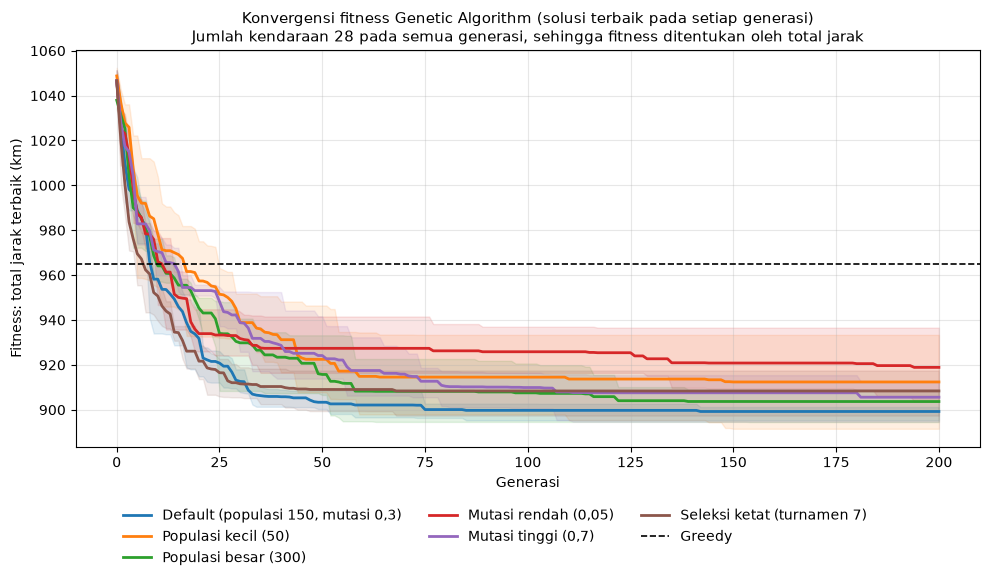

,Konfigurasi,Kendaraan (rata-rata),Jarak akhir rata-rata (km),Jarak terbaik (km),Jarak terburuk (km),Generasi solusi terbaik (rata-rata),Waktu per run (detik)
0,"Default (populasi 150, mutasi 0,3)",28.0,899.23,895.33,901.19,90.00,2.05
1,Populasi kecil (50),28.0,912.39,891.52,933.37,91.67,0.70
2,Populasi besar (300),28.0,903.66,894.51,909.06,109.67,4.19
3,"Mutasi rendah (0,05)",28.0,918.89,903.64,936.58,138.00,1.40
4,"Mutasi tinggi (0,7)",28.0,905.60,894.67,912.60,133.67,4.79
5,Seleksi ketat (turnamen 7),28.0,908.37,897.40,917.47,45.67,1.67


In [91]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def history_to_parts(history, length):
    fitness = np.pad(np.array(history, dtype=float), (0, length - len(history)), mode="edge")
    vehicles = fitness // GA_VEHICLE_PENALTY_M
    distance_km = (fitness % GA_VEHICLE_PENALTY_M) / 1000
    return vehicles, distance_km


length = max(len(run["history"]) for runs in convergence_runs.values() for run in runs)
generations = np.arange(length)
curves = {}
for label, runs in convergence_runs.items():
    parts = [history_to_parts(run["history"], length) for run in runs]
    curves[label] = (np.array([part[0] for part in parts]), np.array([part[1] for part in parts]))

# Fitness = kendaraan x bobot besar + jarak. Jika jumlah kendaraan sama di semua generasi, cukup satu panel jarak.
vehicles_vary = len({int(count) for vehicles, _ in curves.values() for count in np.unique(vehicles)}) > 1
fig, axes = plt.subplots(2 if vehicles_vary else 1, 1, figsize=(10, 8.5 if vehicles_vary else 5.8), sharex=True)
axes = np.atleast_1d(axes)
ax_distance = axes[-1]

summary_rows = []
for color, (label, runs) in zip(plt.cm.tab10.colors, convergence_runs.items()):
    vehicles, distance_km = curves[label]
    if vehicles_vary:
        axes[0].plot(generations, vehicles.mean(axis=0), color=color, linewidth=2, label=label)
        axes[0].fill_between(generations, vehicles.min(axis=0), vehicles.max(axis=0), color=color, alpha=0.12)
    ax_distance.plot(generations, distance_km.mean(axis=0), color=color, linewidth=2, label=label)
    ax_distance.fill_between(generations, distance_km.min(axis=0), distance_km.max(axis=0), color=color, alpha=0.12)

    final_km = [run["distance_km"] for run in runs]
    summary_rows.append(
        {
            "Konfigurasi": label,
            "Kendaraan (rata-rata)": np.mean([run["vehicles"] for run in runs]),
            "Jarak akhir rata-rata (km)": np.mean(final_km),
            "Jarak terbaik (km)": np.min(final_km),
            "Jarak terburuk (km)": np.max(final_km),
            "Generasi solusi terbaik (rata-rata)": np.mean([run["best_generation"] for run in runs]),
            "Waktu per run (detik)": np.mean([run["seconds"] for run in runs]),
        }
    )

if "solution" in globals():
    ax_distance.axhline(solution["total_distance_m"] / 1000, color="black", linestyle="--", linewidth=1.2, label="Greedy")

if vehicles_vary:
    axes[0].axhline(vehicle_lower_bound, color="gray", linestyle=":", linewidth=1.5, label="Batas bawah kendaraan")
    axes[0].set_ylabel("Jumlah kendaraan")
    axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0].set_title("Konvergensi fitness Genetic Algorithm (solusi terbaik pada setiap generasi)")
    ax_distance.set_ylabel("Total jarak (km)")
else:
    only_vehicles = int(next(iter(curves.values()))[0].flat[0])
    ax_distance.set_title(
        "Konvergensi fitness Genetic Algorithm (solusi terbaik pada setiap generasi)\n"
        f"Jumlah kendaraan {only_vehicles} pada semua generasi, sehingga fitness ditentukan oleh total jarak",
        fontsize=11,
    )
    ax_distance.set_ylabel("Fitness: total jarak terbaik (km)")
ax_distance.set_xlabel("Generasi")
for axis in axes:
    axis.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels() if vehicles_vary else ax_distance.get_legend_handles_labels()
if vehicles_vary and "solution" in globals():
    handles.append(ax_distance.get_lines()[-1])
    labels.append("Greedy")
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.12 if not vehicles_vary else 0.09, 1, 1))
plt.show()

display(pd.DataFrame(summary_rows).round(2))